# Global regulators of 3'UTR isoform choice in mature control motor neurons (Nuclear WT, D35)

This notebook finds the RNA-binding proteins (RBPs, from CLIP data) and RNA modifications whose binding sites are associated with 3'UTR isoform choice in the **nuclear fraction of control (WT) motor neurons at D35**. It then characterises these top regulators: how they interact and which pathways they belong to, their gene and protein expression in CTRL vs VCP, how their activity changes between D22 and D35 and over the whole time course, whether they act in both fractions (APA) or only in the nucleus (nuclear retention), how likely they are to form condensates, and how they behave in VCP knock-in cells treated or not with ML240.

The regulators are selected at a single time point (Nuclear WT, D35). Some later sections then follow them over the time course (D0, D3, D7, D14, D22, D35).

**Inputs**
- Welch profiles of every CLIP dataset (`MN_diff/results/3UTR_analysis/CLIP/analysis/welch_{proximal,distal}.csv`) and of RNA modification sites (m1A, m6A, m5C, m7G, Nm, pseudouridine, RNA editing; `MN_diff/results/RNA_modifs/<modif>/welch/analysis/`), merged with `scripts/clip/merge_welch.py`. For each 50-nt bin from −1000 to +200 nt around the proximal (pPAS) or distal (dPAS) poly(A) site, the **Welch score** (`-log10(pval)*dPUD`, column `mean_score_lg10`) is the signed significance of the PUD difference linked to a site in that bin. It is computed per day, fraction and genotype. VCP-R155C and VCP-R191Q are pooled as "VCP".
- Gene-level normalised expression (`df_genes_filtered_normalized.csv`) and proteomics (GSE152983, already log2), parsed with `utrals.expression`.
- Condensate propensity z-scores of RBPs (`ALS_Comp/AxonLoc/Supplementary_tables.csv`, an Excel workbook despite its name, 6th sheet).
- Welch profiles of VCP knock-in cells ± ML240 (`VCP-KI-Ml240/results/3UTR_analysis/CLIP`), loaded with `cliptools`.

**Regions** (used throughout; distances in nt relative to the PAS, defined in the setup cells)
- **Region 1 (R1)**: proximal isoform, [−350, −50] upstream of the pPAS. Score = maximum Welch score in the window, clipped at 0 (enrichment).
- **Region 2 (R2)**: proximal isoform, [0, 150] downstream of the pPAS. Score = minimum Welch score in the window, clipped at 0 (depletion).
- **Region 3 (R3)**: distal isoform, [−350, −50] upstream of the dPAS. Score = maximum of the sign-flipped Welch score, clipped at 0.

The STRING cells are pinned to STRING v12.5 and read STRING's archived responses (`../cache/STRING_v12.5/`, `../cache/STRING_v12.5_responses/`), so the figures are reproduced exactly; network access is only needed for a request that is not archived yet. All figures are saved under `../Figures/Figure_global_regulators_NuclearWT_D35` (one subfolder per analysis, named in each section below), and every saved file is listed with its legend in `../Figures/README.md`. Tables (.csv / .xlsx) are saved under `../Tables/Figure_global_regulators_NuclearWT_D35/` and listed with a description of their columns in `../Tables/README.md`; the top-15 regulators of each region, with their APA / nuclear-retention class, are in `top15_global_regulators_NuclearCTRL_D35_<region>_APA_vs_nuclear_retention_class.csv` (`<region>` = `region1_upstream_pPAS`, `region2_downstream_pPAS` or `region3_upstream_dPAS`).

---

## Contents

The output folder of each section is given relative to `../Figures/Figure_global_regulators_NuclearWT_D35/`; the file names are in each section.

- [Setup and data loading](#setup)
- [Region scores per regulator and condition](#region-matrices)
- [Top 15 regulators per region in Nuclear WT D35](#top-regulators): `top_regulators_selection/`
- [STRING network and pathway enrichment of the top regulators](#string)
    - [STRING protein–protein interaction networks](#string-networks): `top_regulators_STRING_networks/`
    - [Pathway enrichment against the whole genome](#enrichment-genome): `top_regulators_pathway_enrichment/`
- [Gene and protein expression of the top regulators, CTRL vs VCP](#expression): `top_regulators_expression_CTRL_vs_VCP/`
- [Change in regulator activity between D22 and D35](#d22-d35-zscore)
    - [All regulators](#d22-d35-all) (displayed, not saved)
    - [Top regulators only](#d22-d35-top): `top_regulators_activity_D22_to_D35/`
- [Welch score of the top regulators over time (Nuclear WT)](#welch-over-time): `top_regulators_activity_over_time/`
    - [One heatmap per regulator set](#welch-over-time-split)
    - [Row z-score within each region (timing of the peak)](#welch-over-time-row)
- [Correlation between regulator activity and its own gene expression over time](#activity-expression): `top_regulators_activity_vs_expression/`
- [APA vs nuclear retention: nuclear vs cytoplasmic activity of the top regulators](#apa-vs-nr): `top_regulators_APA_vs_nuclear_retention/`
    - [Classification of all regulators](#apa-vs-nr-all)
- [Condensate propensity of APA vs nuclear-retention regulators (Region 2)](#condensates): `top_regulators_condensate_propensity/`
- [Top regulators in VCP knock-in cells ± ML240](#vcp-ki): `top_regulators_VCP-KI_ML240/`
    - [Region 2 depletion of the top Region 2 regulators](#vcp-ki-r2-barplots)
    - [Welch profiles of every CLIP, per fraction](#vcp-ki-profiles)

<a id="setup"></a>
## Setup and data loading

Imports, output folder, colour palette, region boundaries (`positive_proximal_region` = R1, `negative_proximal_region` = R2, `positive_distal_region` = R3; the commented-out lines hold earlier, wider windows), and helpers to shorten CLIP names and find boxplot outliers (1.5 × IQR).

In [1]:
import pandas as pd



from numpy.linalg import svd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from scipy.stats import ttest_ind



import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

import warnings
warnings.filterwarnings("ignore")

palette_bar = ["gray", "#b18ebf", "#35607a"]

In [2]:
figures_subfolder = "../Figures/Figure_global_regulators_NuclearWT_D35"
tables_subfolder = "../Tables/Figure_global_regulators_NuclearWT_D35"
import os
from functools import partial

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure / register_figure save a file and list it, with its legend, in ../Figures/README.md;
# save_table saves a .csv / .xlsx table and lists it, with its description, in ../Tables/README.md
from utrals.paths import PROJECT_DIR, PROTEOMICS_CSV, AXONLOC_CSV  # data locations outside the repository (paths.env)
from utrals import figures
save_figure = partial(figures.save_figure, notebook="Figure_global_regulators_NuclearWT_D35.ipynb")
register_figure = partial(figures.register_figure, notebook="Figure_global_regulators_NuclearWT_D35.ipynb")
save_table = partial(figures.save_table, notebook="Figure_global_regulators_NuclearWT_D35.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run
    

In [3]:
palette_condition = {"Cytoplasmic_WT": "#767676", 
                     "Nuclear_WT":  "#c5c5c5",
                     "Nuclear_VCP": "#d39eff",
                    "Cytoplasmic_VCP": "#8936ce"}

In [4]:
# positive_proximal_region = [-350, 100]
# negative_proximal_region = [0, 100]
# positive_distal_region = [-350, 100]

positive_proximal_region = [-350, -50]
negative_proximal_region = [0, 150]
positive_distal_region = [-350, -50]

In [5]:
def get_clip_name(clip_name):
    if "PTB" in clip_name:
        return "PTB"
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name and "iCLIP" not in clip_name:
        return clip_name.split('_')[0] + "_" + clip_name.split('_')[2]
    else:
        return clip_name.split('-')[1].upper()


## extract the outliers
def get_outliers(serie):
    """Get outliers of a ps.Series.
    Args:
        serie (pd.Series): pd.Serie with numerical values

    Returns:
        ps.Series: Two series with the lower outliers and upper outliers.
    """
    Q1, Q3 = serie.quantile([0.25, 0.75]).values
    lower_bound = Q1 - 1.5*(Q3-Q1)
    upper_bound = Q3 + 1.5*(Q3-Q1)
    return serie[serie < lower_bound], serie[serie > upper_bound]




### Load Welch scores of RBPs and RNA modifications

Loads the proximal and distal Welch tables of all CLIP datasets and of the 7 RNA modifications, and concatenates them into `proximal` and `distal`. The `regulator` column holds the CLIP dataset name, or the modification name (e.g. `m6A`).

In [6]:
# Load RBPs welch
proximal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_proximal.csv", index_col=0)
distal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_distal.csv", index_col=0)

proximal.rename(columns={"CLIP": "regulator"}, inplace=True)
distal.rename(columns={"CLIP": "regulator"}, inplace=True)



# Load modifications welch 
modifs = ["m1A", "m6A", "m5C", "m7G", "Nm", "Pseudo", "RNA-editing"]


welch_distals = []
welch_proximals = []
for modif in modifs:
    path_to_processed_RBPs = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/analysis"
    welch_distal = pd.read_csv(os.path.join(path_to_processed_RBPs, "welch_distal.csv"), index_col=0)
    welch_proximal = pd.read_csv(os.path.join(path_to_processed_RBPs, "welch_proximal.csv"), index_col=0)
    welch_distals.append(welch_distal)
    welch_proximals.append(welch_proximal)
    
welch_proximal = pd.concat(welch_proximals)
welch_distal = pd.concat(welch_distals)

welch_proximal.rename(columns={'CLIP': 'regulator'}, inplace=True)
welch_distal.rename(columns={'CLIP': 'regulator'}, inplace=True)

welch_proximal['regulator'] = welch_proximal['regulator'].apply(lambda x: x.split('hg38.')[1].split('.gff')[0])
welch_distal['regulator'] = welch_distal['regulator'].apply(lambda x: x.split('hg38.')[1].split('.gff')[0])

# Merge modifications and RBPs welch
proximal = pd.concat([proximal,
                      welch_proximal])

distal = pd.concat([distal, welch_distal])

In [7]:
proximal

,dist,Day,Compartment,VCP,mean_score_lg10,Isoform,regulator
0,-1000,D0,Cytoplasmic,VCP,1.517700,Proximal 3'UTR Isoform,SF3A3_1_HepG2
1,-950,D0,Cytoplasmic,VCP,1.506601,Proximal 3'UTR Isoform,SF3A3_1_HepG2
2,-900,D0,Cytoplasmic,VCP,0.462179,Proximal 3'UTR Isoform,SF3A3_1_HepG2
3,-850,D0,Cytoplasmic,VCP,2.182623,Proximal 3'UTR Isoform,SF3A3_1_HepG2
4,-800,D0,Cytoplasmic,VCP,3.873619,Proximal 3'UTR Isoform,SF3A3_1_HepG2
...,...,...,...,...,...,...,...
571,-50,D35,Nuclear,Wildtype,-0.394033,Proximal 3'UTR Isoform,RNA-editing
572,0,D35,Nuclear,Wildtype,0.101144,Proximal 3'UTR Isoform,RNA-editing
573,50,D35,Nuclear,Wildtype,-0.198121,Proximal 3'UTR Isoform,RNA-editing
574,100,D35,Nuclear,Wildtype,0.084015,Proximal 3'UTR Isoform,RNA-editing


<a id="region-matrices"></a>
## Region scores per regulator and condition

For every regulator and condition (`<Compartment>_<Genotype>_<Day>`), takes the extreme Welch score inside each region (see the region definitions at the top) and pivots it into one matrix per region: `matrix_region1`, `matrix_region2`, `matrix_region3` (regulators × conditions, column suffix `_region{1,2,3}`).

`matrix_region2` stores the depletion as a **positive** value. In `matrix_not_scaled` (shown in the next cell) it is negated back, so R2 is **negative** there and in `data_scaled` below. The later sections that use `matrix_region2` directly (D22 vs D35 changes, time course, correlation with expression) keep it positive, so a higher value means a stronger effect in all three regions.

In [8]:
def get_clip_name(clip_name):
    if clip_name in ["m1A", "m6A", "m5C", "m7G", "Nm", "Pseudo", "RNA-editing"]:
        return clip_name
    if "PTB" in clip_name:
        return "PTB"
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name and "iCLIP" not in clip_name:
        return clip_name.split('_')[0] + "_" + clip_name.split('_')[2]
    else:
        return clip_name.split('-')[1].upper()


## extract the outliers
def get_outliers(serie):
    """Get outliers of a ps.Series.
    Args:
        serie (pd.Series): pd.Serie with numerical values

    Returns:
        ps.Series: Two series with the lower outliers and upper outliers.
    """
    Q1, Q3 = serie.quantile([0.25, 0.75]).values
    lower_bound = Q1 - 1.5*(Q3-Q1)
    upper_bound = Q3 + 1.5*(Q3-Q1)
    return serie[serie < lower_bound], serie[serie > upper_bound]



df = pd.concat([proximal, distal])

df.replace({"Wildtype": "WT"}, inplace=True)
df.reset_index(inplace=True, drop=True)
df.replace({"VCP-R155C": "VCP", "VCP-R191Q": 'VCP'}, inplace=True)

region = positive_proximal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].idxmax()]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)

matrix_region1 = df_int.pivot(index='regulator', columns='Condition', values='mean_score_lg10')
matrix_region1.columns = [col + '_region1' for col in matrix_region1.columns]

region = negative_proximal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].idxmin()]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(upper=0)

matrix_region2 = -df_int.pivot(index='regulator', columns='Condition', values='mean_score_lg10')
matrix_region2.columns = [col + '_region2' for col in matrix_region2.columns]

region = positive_distal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Distal 3'UTR Isoform")]
df_region["mean_score_lg10"] = - df_region["mean_score_lg10"]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].apply(lambda x: x.idxmax())]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)

matrix_region3 = df_int.pivot(index='regulator', columns='Condition', values='mean_score_lg10')
# matrix_region3 = -matrix_region3
matrix_region3.columns = [col + '_region3' for col in matrix_region3.columns]




matrix_not_scaled = pd.concat([matrix_region1, -matrix_region2, matrix_region3], axis=1)


In [9]:
matrix_not_scaled

,Cytoplasmic_VCP_D0_region1,Cytoplasmic_VCP_D14_region1,Cytoplasmic_VCP_D22_region1,Cytoplasmic_VCP_D3_region1,Cytoplasmic_VCP_D35_region1,Cytoplasmic_VCP_D7_region1,Cytoplasmic_WT_D0_region1,Cytoplasmic_WT_D14_region1,Cytoplasmic_WT_D22_region1,Cytoplasmic_WT_D3_region1,...,Nuclear_VCP_D22_region3,Nuclear_VCP_D3_region3,Nuclear_VCP_D35_region3,Nuclear_VCP_D7_region3,Nuclear_WT_D0_region3,Nuclear_WT_D14_region3,Nuclear_WT_D22_region3,Nuclear_WT_D3_region3,Nuclear_WT_D35_region3,Nuclear_WT_D7_region3
regulator,,,,,,,,,,,,,,,,,,,,,
AARS_1_K652,7.991412,7.935531,5.601863,6.537581,5.527530,8.237605,7.472853,6.897531,4.757131,7.511461,...,9.051157,18.369278,12.977490,17.594246,14.549127,11.798024,8.290304,18.000661,12.199611,19.252655
AARS_2_K652,14.532161,16.115658,11.885651,13.755186,12.303633,14.216967,15.131453,16.395570,13.360415,15.662153,...,10.823248,16.978661,12.529018,15.108621,13.324203,13.868043,10.890812,15.964527,9.642696,15.669741
AGGF1_1_HepG2,18.961118,18.153747,15.625984,15.924507,16.201774,16.380073,20.395729,18.525928,15.829182,17.449314,...,13.086396,18.229161,10.926305,11.759445,13.303341,20.989758,16.027376,17.446168,5.759978,13.080116
AGGF1_1_K652,22.857554,21.425265,14.682154,19.049823,14.727391,20.651760,24.513231,18.179511,14.318881,20.761707,...,17.911941,26.202337,21.225450,23.147555,19.439545,22.556854,20.192502,27.022287,15.970974,23.063221
AGGF1_2_HepG2,16.122913,15.589067,8.692379,14.217448,10.329178,14.623480,15.945513,12.784894,8.903025,14.605177,...,23.152006,33.933582,27.943790,30.015912,29.718377,27.605448,25.079024,33.076802,19.583159,29.184729
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
all-hnRNPL-Hela-_iCLIP,31.839007,26.490629,15.866170,24.425580,18.070771,27.375379,32.650610,24.573925,17.792960,24.704596,...,36.780444,58.750749,46.025466,62.519321,55.252804,39.787906,34.028472,61.566564,44.066729,63.368632
hnrnpc-bestof_iCLIP,0.405160,0.852636,0.013666,0.378964,0.000000,0.375588,1.093401,0.510512,0.000000,0.434112,...,13.718332,26.982335,18.548225,26.764156,22.362801,11.186458,9.483277,22.648390,20.174823,25.673568
m1A,2.012178,1.773772,0.908088,2.232875,0.746481,1.864906,1.890013,1.331864,0.878384,1.743009,...,0.778341,0.404175,0.427932,0.444974,0.463618,0.424404,0.661268,0.469060,0.288308,0.325432


<a id="top-regulators"></a>
## Top 15 regulators per region in Nuclear WT D35

Takes the Nuclear WT D35 column of each region and divides it by its standard deviation across regulators. Infinite values, which come from p = 0 in the pipeline, are set to NaN first. The boxplot shows the scaled scores per region, and the cell prints how many regulators are outliers (1.5 × IQR). Saved as `top_regulators_selection/boxplot_scaled_welch_score_per_region_NuclearWT_D35.pdf`.

The next cells define the **top 15 regulators of each region**: the highest scores for R1 and R3, and the most negative for R2. Only the best CLIP dataset of each RBP is kept, so each list holds 15 distinct RBPs (or modifications).
- `R1_top15`, `R2_top15`, `R3_top15`: RBP / modification names, used for STRING and expression.
- `R1_top15_long_names`, …: the matching CLIP dataset names, used to look up Welch scores in the later sections.

The outlier lists `R1`, `R2`, `R3` are computed in the first of these cells but are not used afterwards.


Outliers Summary:
Region 1 - Lower: 0, Upper: 11
Region 2 - Lower: 26, Upper: 0
Region 3 - Lower: 0, Upper: 41


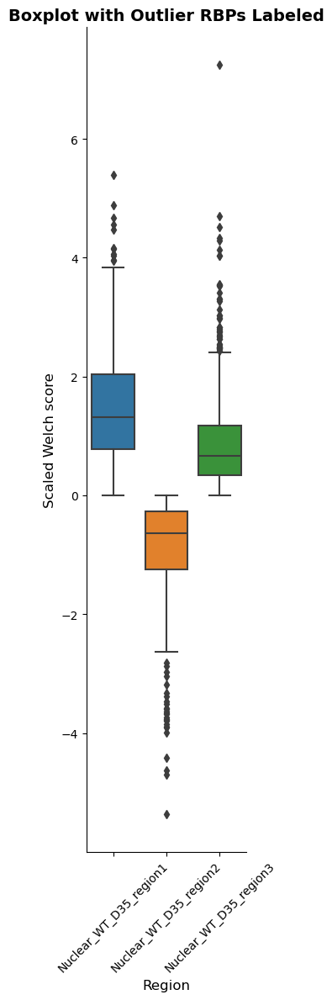

In [10]:
# matrix_not_scaled["RBP_name"] = matrix_not_scaled.index.map(get_clip_name)
# df_matrix_merged = matrix_not_scaled.groupby("RBP_name").mean()

data = matrix_not_scaled[["Nuclear_WT_D35_region1", 
                         "Nuclear_WT_D35_region2", 
                         "Nuclear_WT_D35_region3"]]
# Divide by per-column std, skipping NaNs
# Replace inf before scaling (1 inf present in region1 and region2 from the pipeline)
data = data.replace([np.inf, -np.inf], np.nan)
col_stds = data.apply(lambda col: np.nanstd(col.dropna(), ddof=1))
data_scaled = data / col_stds
# data_scaled["Nuclear_WT_D35_region1"] = -data_scaled["Nuclear_WT_D35_region1"]  # Invert region1 for visualization
# data_scaled["Nuclear_WT_D35_region2"] = -data_scaled["Nuclear_WT_D35_region2"]  # Invert region2 for visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Create a large figure for clear visualization
fig, ax = plt.subplots(figsize=(3, 12))
sns.boxplot(data=data_scaled, ax=ax)

# Get outliers for each region
lower_out_r1, upper_out_r1 = get_outliers(data_scaled["Nuclear_WT_D35_region1"])
lower_out_r2, upper_out_r2 = get_outliers(data_scaled["Nuclear_WT_D35_region2"])
lower_out_r3, upper_out_r3 = get_outliers(data_scaled["Nuclear_WT_D35_region3"])

ax.set_ylabel('Scaled Welch score', fontsize=12)
ax.set_xlabel('Region', fontsize=12)
ax.set_title('Boxplot with Outlier RBPs Labeled', fontsize=14, weight='bold')
plt.xticks(rotation=45)
sns.despine()
plt.tight_layout()

save_figure(f"{figures_subfolder}/top_regulators_selection/boxplot_scaled_welch_score_per_region_NuclearWT_D35.pdf",
            legend="Welch score of every regulator (CLIP datasets and RNA modifications) in the nuclear fraction "
                   "of CTRL motor neurons at D35, per region: R1 = max score in [-350, -50] nt upstream of the pPAS; "
                   "R2 = min score in [0, +150] nt downstream of the pPAS (negative = depletion); R3 = max of the "
                   "sign-flipped score in [-350, -50] nt upstream of the dPAS. Scores clipped at 0 in the expected "
                   "direction and divided by the SD of the region across regulators. Boxplots, whiskers 1.5 x IQR. "
                   "The top 15 regulators of each region (one CLIP per RBP) are picked from these values.")
# Print summary
print(f"\nOutliers Summary:")
print(f"Region 1 - Lower: {len(lower_out_r1)}, Upper: {len(upper_out_r1)}")
print(f"Region 2 - Lower: {len(lower_out_r2)}, Upper: {len(upper_out_r2)}")
print(f"Region 3 - Lower: {len(lower_out_r3)}, Upper: {len(upper_out_r3)}")

In [11]:
def get_RBP_name(clip_name):
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name:
        return clip_name.split('_')[0]        
    else:
        return clip_name.split('-')[1].upper()
    
R1 = [get_RBP_name(name) for name in lower_out_r1.index.tolist()]
R2 = [get_RBP_name(name) for name in upper_out_r2.index.tolist()]
R3 = [get_RBP_name(name) for name in upper_out_r3.index.tolist()]

R1_top10 = data_scaled["Nuclear_WT_D35_region1"]

In [12]:
d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region1"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R1_top15 = d.sort_values(by='Nuclear_WT_D35_region1', ascending=False).dropna().drop_duplicates(['RBP_short']).head(15)['RBP_short'].values.tolist()

d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region2"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R2_top15 = d.sort_values(by='Nuclear_WT_D35_region2').dropna().drop_duplicates(['RBP_short']).head(15)['RBP_short'].values.tolist()


d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region3"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R3_top15 = d.sort_values(by='Nuclear_WT_D35_region3', ascending=False).dropna().drop_duplicates(['RBP_short']).head(15)['RBP_short'].values.tolist()


In [13]:
d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region1"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R1_top15_long_names = d.sort_values(by='Nuclear_WT_D35_region1', ascending=False).dropna().drop_duplicates(['RBP_short']).head(15).index.tolist()

d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region2"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R2_top15_long_names = d.sort_values(by='Nuclear_WT_D35_region2').dropna().drop_duplicates(['RBP_short']).head(15).index.tolist()


d = pd.DataFrame(data_scaled["Nuclear_WT_D35_region3"])
d['RBP_short'] =  [get_RBP_name(name) for name in d.index]
R3_top15_long_names = d.sort_values(by='Nuclear_WT_D35_region3', ascending=False).dropna().drop_duplicates(['RBP_short']).head(15).index.tolist()


In [14]:
d

,Nuclear_WT_D35_region3,RBP_short
regulator,,
AARS_1_K652,0.628327,AARS
AARS_2_K652,0.496636,AARS
AGGF1_1_HepG2,0.296661,AGGF1
AGGF1_1_K652,0.822567,AGGF1
AGGF1_2_HepG2,1.008609,AGGF1
...,...,...
all-hnRNPL-Hela-_iCLIP,2.269607,HNRNPL
hnrnpc-bestof_iCLIP,1.039082,HNRNPC
m1A,0.014849,m1A


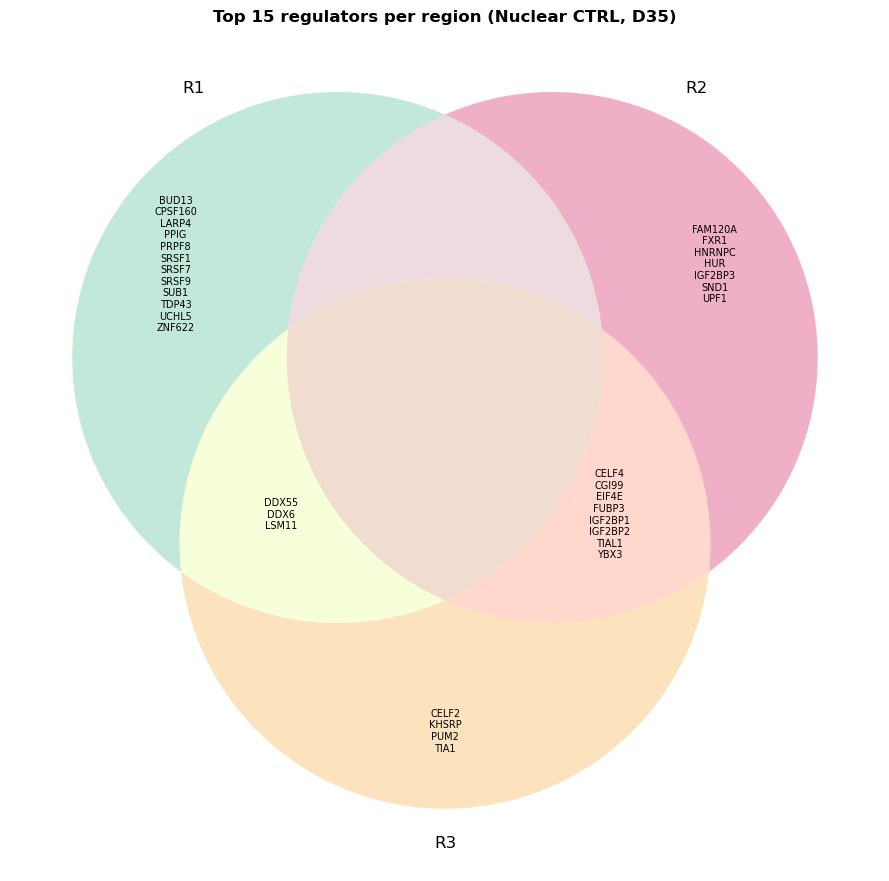

R1 only (12): BUD13, CPSF160, LARP4, PPIG, PRPF8, SRSF1, SRSF7, SRSF9, SUB1, TDP43, UCHL5, ZNF622
R2 only (7): FAM120A, FXR1, HNRNPC, HUR, IGF2BP3, SND1, UPF1
R3 only (4): CELF2, KHSRP, PUM2, TIA1
R1 & R2 (0): -
R1 & R3 (3): DDX55, DDX6, LSM11
R2 & R3 (8): CELF4, CGI99, EIF4E, FUBP3, IGF2BP1, IGF2BP2, TIAL1, YBX3
R1 & R2 & R3 (0): -


In [15]:
# ---- Venn diagram of the top-15 regulators of R1 / R2 / R3 (RBP_short names) ----
from matplotlib_venn import venn3_unweighted

venn_sets = {"R1": set(R1_top15), "R2": set(R2_top15), "R3": set(R3_top15)}
A, B, C = venn_sets.values()
venn_parts = {   # matplotlib_venn subset ids: '100' = R1 only, '110' = R1 & R2 only, ...
    "100": A - B - C, "010": B - A - C, "001": C - A - B,
    "110": (A & B) - C, "101": (A & C) - B, "011": (B & C) - A,
    "111": A & B & C,
}
part_labels = {"100": "R1 only", "010": "R2 only", "001": "R3 only",
               "110": "R1 & R2", "101": "R1 & R3", "011": "R2 & R3", "111": "R1 & R2 & R3"}

fig, ax = plt.subplots(figsize=(9, 9))
# Unweighted: classic symmetric 3-circle layout (region sizes do not reflect counts)
v = venn3_unweighted([A, B, C], set_labels=list(venn_sets), ax=ax,
                     set_colors=("#51be92", "#d31c5d", "#faaf43"), alpha=0.35)
for part_id, members in venn_parts.items():
    label = v.get_label_by_id(part_id)
    if label is not None:
        label.set_text("\n".join(sorted(members)))
        label.set_fontsize(7)
ax.set_title("Top 15 regulators per region (Nuclear CTRL, D35)", fontsize=12, weight="bold")
plt.tight_layout()
save_figure(f"{figures_subfolder}/top_regulators_selection/venn_top15_regulators_R1_R2_R3_NuclearWT_D35.pdf",
            legend="Overlap of the top 15 regulators of R1 (red), R2 (orange) and R3 (blue) in the nuclear fraction "
                   "of CTRL motor neurons at D35, at the RBP level (RBP_short names: one CLIP dataset per RBP; RNA "
                   "modifications included). Each region lists the regulators it contains. Unweighted layout: "
                   "region sizes do not reflect the number of regulators.")
plt.show()

for part_id, members in venn_parts.items():
    print(f"{part_labels[part_id]} ({len(members)}): {', '.join(sorted(members)) or '-'}")


<a id="string"></a>
## STRING network and pathway enrichment of the top regulators

Helper functions for the STRING API (human, taxon 9606):
- **Network**: only edges supported by the *experiments* or *databases* channels are kept, with max(escore, dscore) ≥ 0.4 (medium confidence). Aliases (e.g. HUR → ELAVL1) are resolved to STRING's preferred names, so a node keeps the same identity and colour whichever alias was used.
- **Enrichment**: KEGG, Reactome and GO Biological Process terms. The cell computes *strength* = log10(observed / expected) and *signal* = harmonic mean of strength and −log10(FDR). Redundant terms (Jaccard similarity of their gene sets ≥ 0.5) are collapsed, keeping the most significant one.
- **Bubble plot** (`plot_enrichment_combined`): the union of the top 10 terms (by FDR) of each region. Bubble size = −log10(FDR), colour = signal.

The functions are imported from `utrals.string_analysis`. STRING is pinned to release 12.5 (`version-12-5.string-db.org`) and the raw response of every request is archived in `../cache/STRING_v12.5/` (git-tracked) the first time; later runs read the archive and never contact STRING, so the figures are reproduced exactly.

In [16]:
# STRING network / enrichment functions, shared with Figure_regulators_lengthening.ipynb (utrals.string_analysis). Every STRING
# request is pinned to STRING v12.5 and its raw response archived in ../cache/STRING_v12.5/, read back on later runs.
import matplotlib.patches as mpatches
from utrals.string_analysis import GROUP_COLORS, get_string_network, map_to_string, resolve_string_ids, get_string_enrichment, build_node_colors, draw_pie_nodes, get_preferred_names, plot_string_network, dedupe_redundant_terms, get_enrichment_df, plot_enrichment_combined

<a id="string-networks"></a>
### STRING protein–protein interaction networks

RNA modifications are removed from the top-15 lists (`R*_top15_no_mod`). One network per region, with isolated proteins placed on an outer ring. Nodes are coloured by the top-15 list(s) they belong to (R1 red, R2 orange, R3 blue); a protein in several lists is drawn as a pie. Saved as `top_regulators_STRING_networks/STRING_network_top15_R{1,2,3}_regulators.pdf`.

In [17]:
R1_top15_no_mod = [reg for reg in R1_top15 if reg not in modifs]
R2_top15_no_mod = [reg for reg in R2_top15 if reg not in modifs]
R3_top15_no_mod = [reg for reg in R3_top15 if reg not in modifs]

  R1 (proximal promoter binding) — no qualifying interactions: ['CPSF1', 'DDX55', 'LSM11', 'TARDBP', 'UCHL5', 'ZNF622']


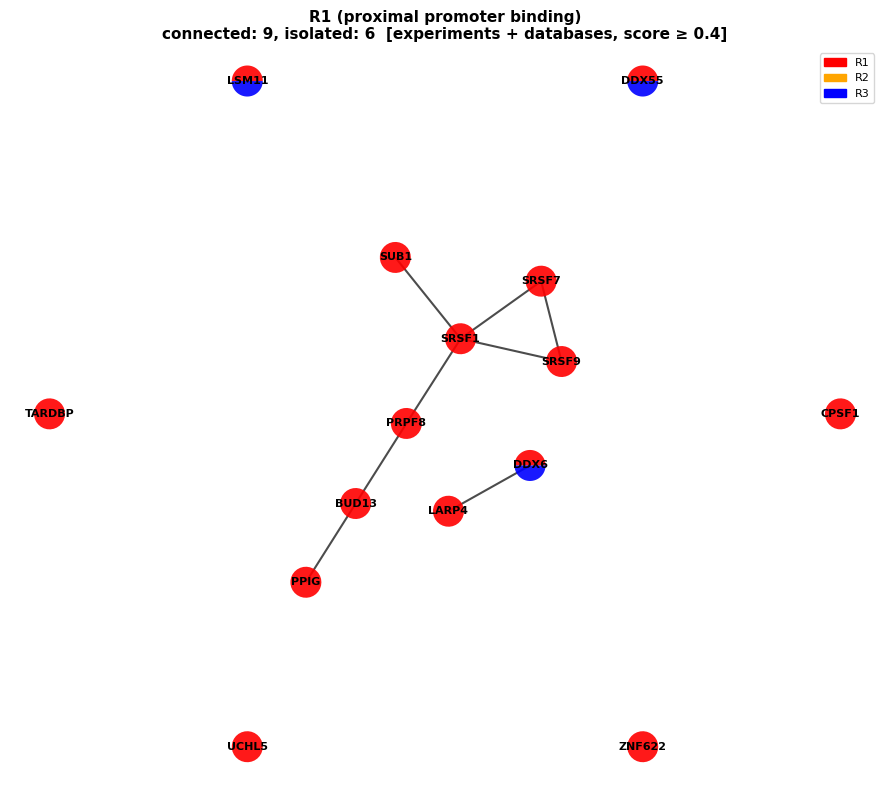

R1 (proximal promoter binding): 8 interactions found

  R2 (proximal depletion) — no qualifying interactions: ['FUBP3']


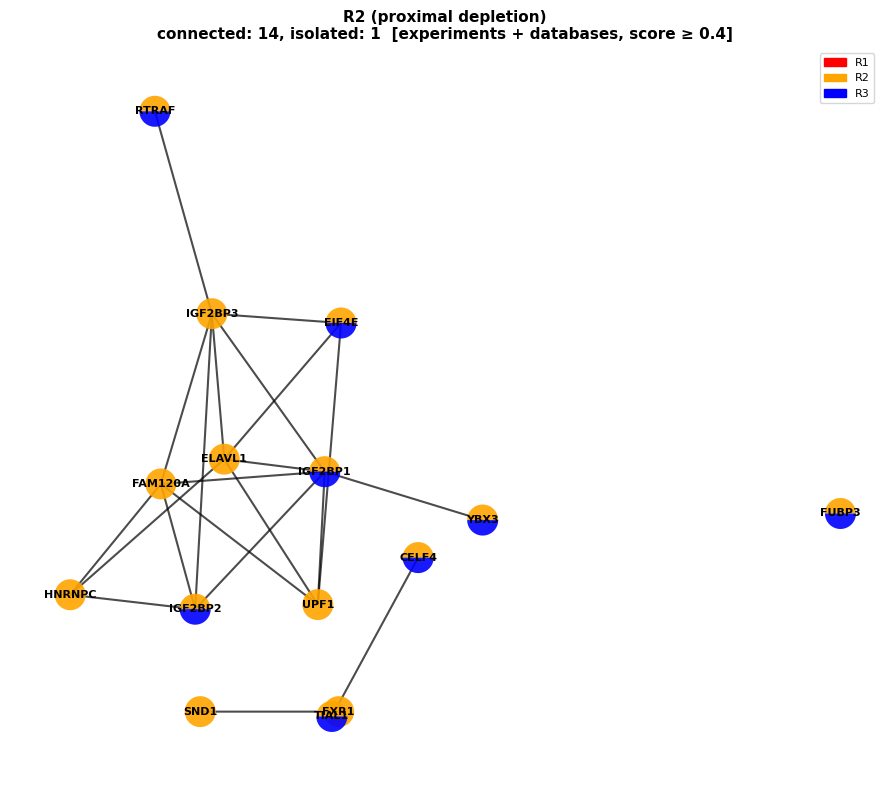

R2 (proximal depletion): 21 interactions found

  R3 (distal binding) — no qualifying interactions: ['RTRAF', 'DDX55', 'LSM11', 'PUM2', 'TIA1']


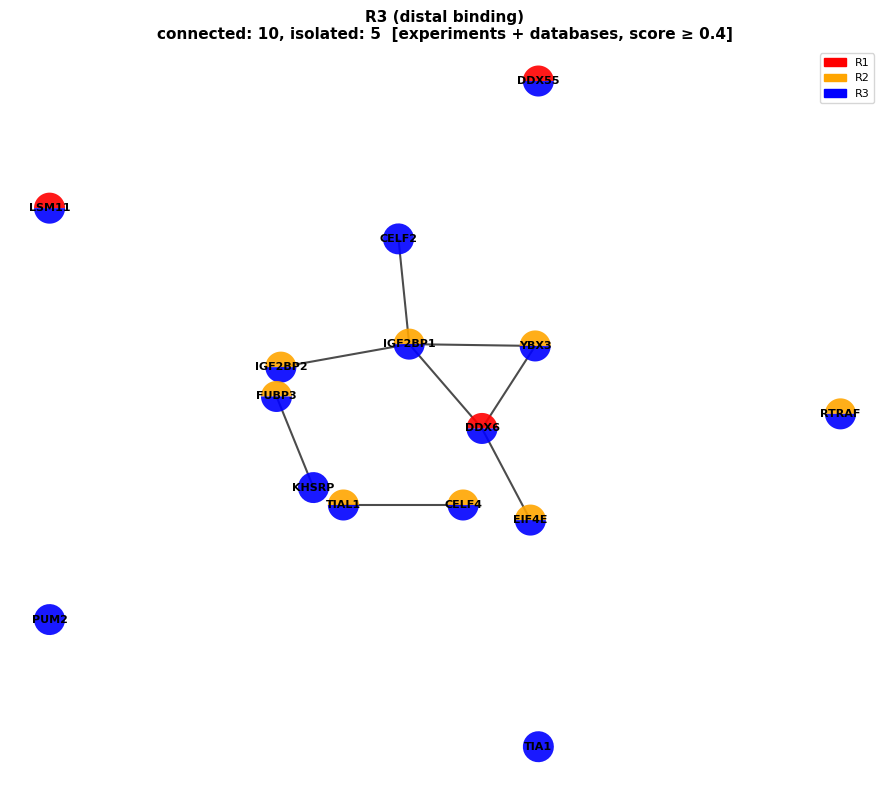

R3 (distal binding): 8 interactions found



In [18]:


region_genes = {
    "R1 (proximal promoter binding)": R1_top15_no_mod,
    "R2 (proximal depletion)": R2_top15_no_mod,
    "R3 (distal binding)": R3_top15_no_mod,
}

network_dir = f"{figures_subfolder}/top_regulators_STRING_networks"
os.makedirs(network_dir, exist_ok=True)

group_lists = {"R1": R1_top15_no_mod, "R2": R2_top15_no_mod, "R3": R3_top15_no_mod}
all_genes = set(R1_top15_no_mod) | set(R2_top15_no_mod) | set(R3_top15_no_mod)
node_colors = build_node_colors(all_genes, group_lists)

legend_handles = [mpatches.Patch(color=color, label=label)
                   for label, color in GROUP_COLORS.items()]

string_networks = {}
for region_name, genes in region_genes.items():
    fig, ax = plt.subplots(figsize=(9, 8))
    G, df_net = plot_string_network(genes, region_name, ax=ax, node_colors=node_colors)
    ax.legend(handles=legend_handles, loc="upper right", fontsize=8, frameon=True)
    string_networks[region_name] = (G, df_net)
    plt.tight_layout()
    safe_name = region_name.split(" ")[0]
    save_figure(f"{network_dir}/STRING_network_top15_{safe_name}_regulators.pdf",
                legend=f"STRING protein-protein interaction network of the top 15 {safe_name} regulators "
                       "(Nuclear CTRL, D35; RNA modifications excluded). Edges: experiments or databases evidence "
                       "with max(escore, dscore) >= 0.4; proteins without such an edge sit on the outer ring. "
                       "Node colour = top-15 list(s) the protein belongs to (R1 red, R2 orange, R3 blue; "
                       "a pie = several lists).")
    plt.show()
    print(f"{region_name}: {len(df_net)} interactions found\n")

<a id="enrichment-genome"></a>
### Pathway enrichment against the whole genome

Enrichment of the top 15 regulators of each region (KEGG, GO Biological Process), shown as one bubble plot with one column per region. Saved as `top_regulators_pathway_enrichment/bubble_enrichment_top15_regulators_genome_background.pdf`. The full list of significant terms (FDR < 0.05) of each region, with their source database (also Reactome, GO Cellular Component and GO Molecular Function, which are not plotted), is saved as `../Tables/Figure_global_regulators_NuclearWT_D35/STRING_enrichment_KEGG_Reactome_GO_significant_terms_top15_global_regulators_per_region_NuclearCTRL_D35_genome_background.xlsx` (one sheet for all regions, one per region; `redundant` = collapsed in the plot (plotted sources only), `in_plot` = drawn).

STRING names the Reactome category `RCTM`, the plot uses `KEGG` and `Process`; the table adds `RCTM`, `Component` and `Function`.

The cell builds `background_rbps` (all regulators in the analysis) but calls the plot with `background_genes=None`, so the background used is STRING's whole-genome default.

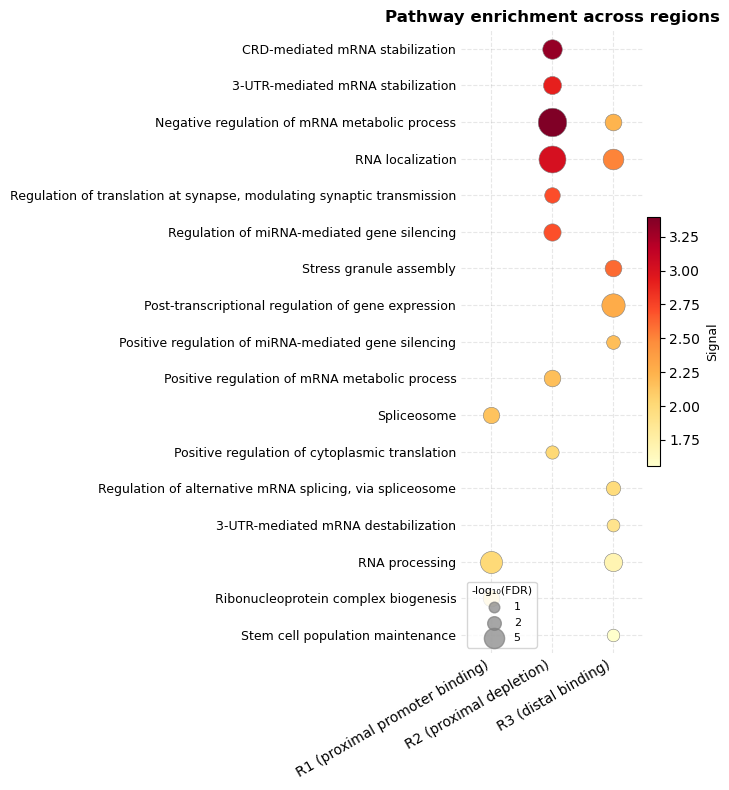

Saved 147 significant terms to ../Tables/Figure_global_regulators_NuclearWT_D35/STRING_enrichment_KEGG_Reactome_GO_significant_terms_top15_global_regulators_per_region_NuclearCTRL_D35_genome_background.xlsx
source                          GO Molecular Function  Reactome  \
region                                                            
R1 (proximal promoter binding)                      3         8   
R2 (proximal depletion)                             8         2   
R3 (distal binding)                                 6         2   

source                          GO Biological Process  GO Cellular Component  \
region                                                                         
R1 (proximal promoter binding)                     14                     11   
R2 (proximal depletion)                            38                      9   
R3 (distal binding)                                36                      9   

source                          KEGG  
region           

,region,description,log_fdr,signal
0,R1 (proximal promoter binding),RNA processing,6.032452,2.001663
1,R1 (proximal promoter binding),Ribonucleoprotein complex biogenesis,3.259637,1.828170
2,R1 (proximal promoter binding),Spliceosome,3.107905,2.150146
3,R2 (proximal depletion),Negative regulation of mRNA metabolic process,10.419075,3.394140
4,R2 (proximal depletion),RNA localization,9.294136,3.016596
5,R2 (proximal depletion),CRD-mediated mRNA stabilization,4.632644,3.315151
6,R2 (proximal depletion),3-UTR-mediated mRNA stabilization,3.886057,2.906585
7,R2 (proximal depletion),Regulation of miRNA-mediated gene silencing,3.508638,2.697613
8,R2 (proximal depletion),Positive regulation of mRNA metabolic process,3.229148,2.169515
9,R2 (proximal depletion),"Regulation of translation at synapse, modulati...",2.744727,2.705950


In [19]:
enrichment_dir = f"{figures_subfolder}/top_regulators_pathway_enrichment"
os.makedirs(enrichment_dir, exist_ok=True)

# Background = all other RBPs analyzed here (top-15 vs. the rest of the panel),
# instead of the whole genome/proteome.
background_rbps = [rbp.split('_')[0] for rbp in data_scaled.index.tolist()]
background_rbps = ["TARDBP" if "TDP43" in rbp else rbp for rbp in background_rbps]

# STRING category codes (Reactome is "RCTM" in the API, not "Reactome").
# The plot uses PLOT_SOURCES only; the table lists every source in ENRICHMENT_SOURCES.
ENRICHMENT_SOURCES = {
    "KEGG": "KEGG",
    "RCTM": "Reactome",
    "Process": "GO Biological Process",
    "Component": "GO Cellular Component",
    "Function": "GO Molecular Function",
}
PLOT_SOURCES = ("KEGG", "Process")

fig, ax = plt.subplots(figsize=(7, 8))
df_enrich_combined = plot_enrichment_combined(
    region_genes,
    top_n=10,
    categories=PLOT_SOURCES,
    background_genes=None,
    jaccard_threshold=0.5,
    ax=ax,
)
plt.tight_layout()
save_figure(f"{enrichment_dir}/bubble_enrichment_top15_regulators_genome_background.pdf",
            legend="STRING enrichment (KEGG, GO Biological Process) of the top 15 "
                   "regulators of each region (columns; Nuclear CTRL, D35; RNA modifications excluded), against the "
                   "whole-genome background. Rows = union of the 10 most significant terms (FDR) of each region; "
                   "near-duplicate terms (gene-set Jaccard >= 0.5) collapsed to the most significant one. Bubble size = "
                   "-log10(FDR); colour = STRING signal (harmonic mean of strength = log10(observed/expected) and "
                   "-log10(FDR)). Full list of significant terms (also Reactome, GO Cellular Component and GO Molecular Function): "
                   "../Tables/Figure_global_regulators_NuclearWT_D35/STRING_enrichment_KEGG_Reactome_GO_significant_terms_top15_global_regulators_per_region_NuclearCTRL_D35_genome_background.xlsx.")
plt.show()

# ---- Table: every significant term (FDR < 0.05) of each region, before redundancy collapsing ----
# jaccard_threshold > 1 keeps all terms. For the plotted sources, 'redundant' flags the terms
# the plot collapses (Jaccard >= 0.5 with a more significant term; empty for the other sources)
# and 'in_plot' those drawn in the bubble plot.
table_rows = []
for region_name, genes in region_genes.items():
    df_full = get_enrichment_df(list(set(genes)), categories=tuple(ENRICHMENT_SOURCES),
                                background_genes=None, jaccard_threshold=1.01)
    if df_full.empty:
        continue
    df_full = df_full[df_full["fdr"] < 0.05].sort_values("fdr")
    is_plot_source = df_full["category"].isin(PLOT_SOURCES)
    kept = set(dedupe_redundant_terms(df_full[is_plot_source], jaccard_threshold=0.5)["term"])
    plotted = set(df_enrich_combined.loc[df_enrich_combined["region"] == region_name, "description"])
    table_rows.append(pd.DataFrame({
        "region":                 region_name,
        "source":                 df_full["category"].map(ENRICHMENT_SOURCES),
        "term_id":                df_full["term"],
        "description":            df_full["description"],
        "n_genes":                df_full["number_of_genes"],
        "n_genes_in_background":  df_full["number_of_genes_in_background"],
        "strength_log10_obs_exp": df_full["strength"],
        "p_value":                df_full["p_value"],
        "fdr":                    df_full["fdr"],
        "signal":                 df_full["signal"],
        "genes":                  df_full["preferredNames"].apply(", ".join),
        "redundant":              (~df_full["term"].isin(kept)).astype(object).where(is_plot_source),
        "in_plot":                df_full["description"].isin(plotted) & is_plot_source,
    }))
enrichment_table = pd.concat(table_rows, ignore_index=True)

table_path = f"{tables_subfolder}/STRING_enrichment_KEGG_Reactome_GO_significant_terms_top15_global_regulators_per_region_NuclearCTRL_D35_genome_background.xlsx"
save_table({"All regions": enrichment_table,
            **{region_name.split(" ")[0]: df_r for region_name, df_r in enrichment_table.groupby("region", sort=False)}},
           table_path, index=False,
           legend="STRING enrichment (KEGG, Reactome, GO Biological Process, GO Cellular Component, GO Molecular "
                  "Function; whole-genome background) of the top 15 regulators of each region (Nuclear CTRL, D35; RNA "
                  "modifications excluded): every term with FDR < 0.05, before redundancy collapsing. Sheets: all "
                  "regions, then one per region (R1, R2, R3). Columns: region, source database, term ID and "
                  "description, number of genes of the list and of the background annotated with the term, strength "
                  "(log10 observed/expected), p-value, FDR, STRING signal, member genes; redundant = term collapsed in "
                  "the bubble plot (gene-set Jaccard >= 0.5 with a more significant term; KEGG and GO Biological "
                  "Process only, empty for the other sources); in_plot = drawn in "
                  "bubble_enrichment_top15_regulators_genome_background.pdf.")
print(f"Saved {len(enrichment_table)} significant terms to {table_path}")
print(enrichment_table.groupby(["region", "source"], sort=False).size().unstack(fill_value=0))
df_enrich_combined

<a id="expression"></a>
## Gene and protein expression of the top regulators, CTRL vs VCP

Loads gene expression and proteomics with `load_expression_metadata`, and uses the shared helpers of `utrals.expression`. `RBP_TO_SYMBOL` maps CLIP names to gene symbols, e.g. TDP43 → TARDBP.

For each region's top-15 list (modifications excluded), `plot_wt_vs_vcp_heatmap` draws the mean expression per day, WT and VCP side by side. Each row is z-scored jointly over the 12 columns (6 days × 2 genotypes), so levels can be compared between genotypes. Rows are clustered on the WT panel, and `*` marks days where WT and VCP differ (Welch's t-test on replicates, p < 0.05, uncorrected).
- Gene expression (log2(normalised counts + 1)), nuclear fraction: `heatmap_gene_expression_Nuclear_top15_R{1,2,3}_regulators_CTRL_vs_VCP.pdf`.
- Protein expression (log2), nuclear and cytoplasmic fractions: `heatmap_protein_expression_{Nuclear,Cytoplasmic}_top15_R{1,2,3}_regulators_CTRL_vs_VCP.pdf`.
- Differential gene expression VCP vs CTRL at D35, nuclear fraction: log2FC (mean VCP − mean CTRL of log2 expression) and Welch's t-test per regulator, one box per top-15 list, with every RBP that has a CLIP dataset as a reference: `boxplot_log2FC_gene_expression_Nuclear_D35_top15_regulators_VCP_vs_CTRL.pdf`.
- CELF4 gene expression over time, CTRL vs VCP, nuclear and cytoplasmic fractions (mean ± SD of replicates): `lineplot_gene_expression_CELF4_over_time_CTRL_vs_VCP.pdf`.

All files are saved in `top_regulators_expression_CTRL_vs_VCP/`.

In [20]:
## Load gene expression and protein expression
# Parsed with utrals.expression: sample columns
# "{Sample}_{Day}_{Compartment}_{Genotype}" -> metadata, VCP-R155C / VCP-R191Q collapsed to "VCP".
from utrals.expression import load_expression_metadata, gene_expression_over_time, DAY_ORDER

expr_path = f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv"
prot_path = f"{PROTEOMICS_CSV}"

df_genes, meta_genes = load_expression_metadata(expr_path)
df_prot, meta_prot = load_expression_metadata(prot_path)   # already log2 + median-normalised


In [21]:
# Shared expression helpers (utrals.expression, also used by Figure_regulators_lengthening.ipynb):
# RBP_TO_SYMBOL, expression_long, plot_wt_vs_vcp_heatmap
from utrals.rbp_names import RBP_TO_SYMBOL
from utrals.expression import expression_long, plot_wt_vs_vcp_heatmap


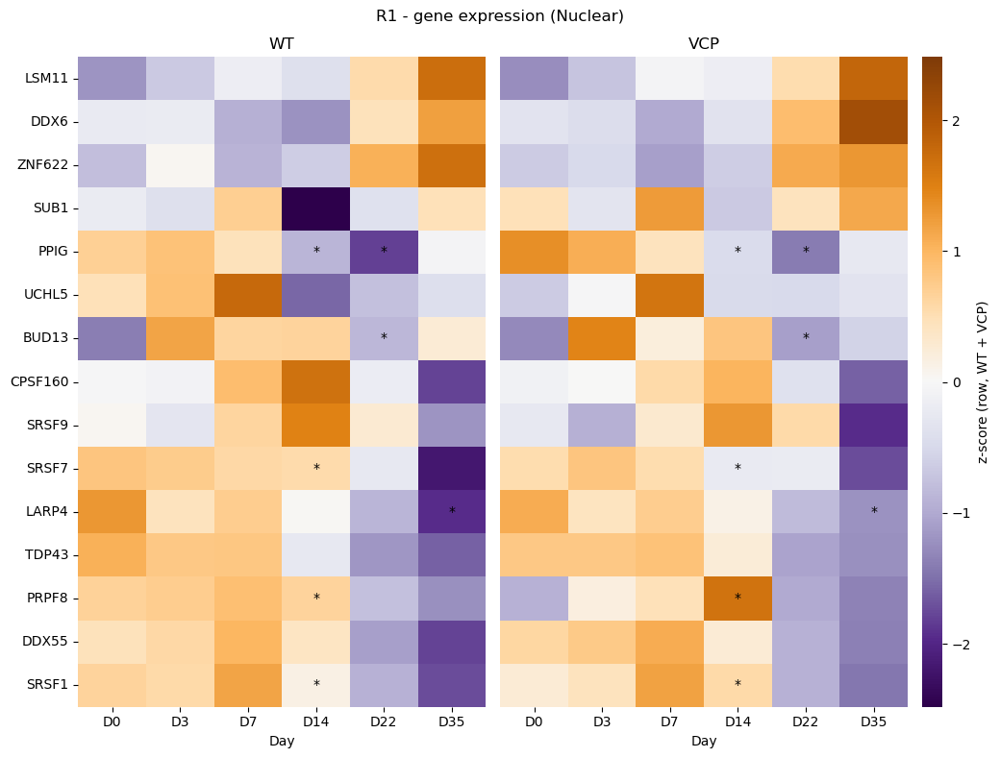

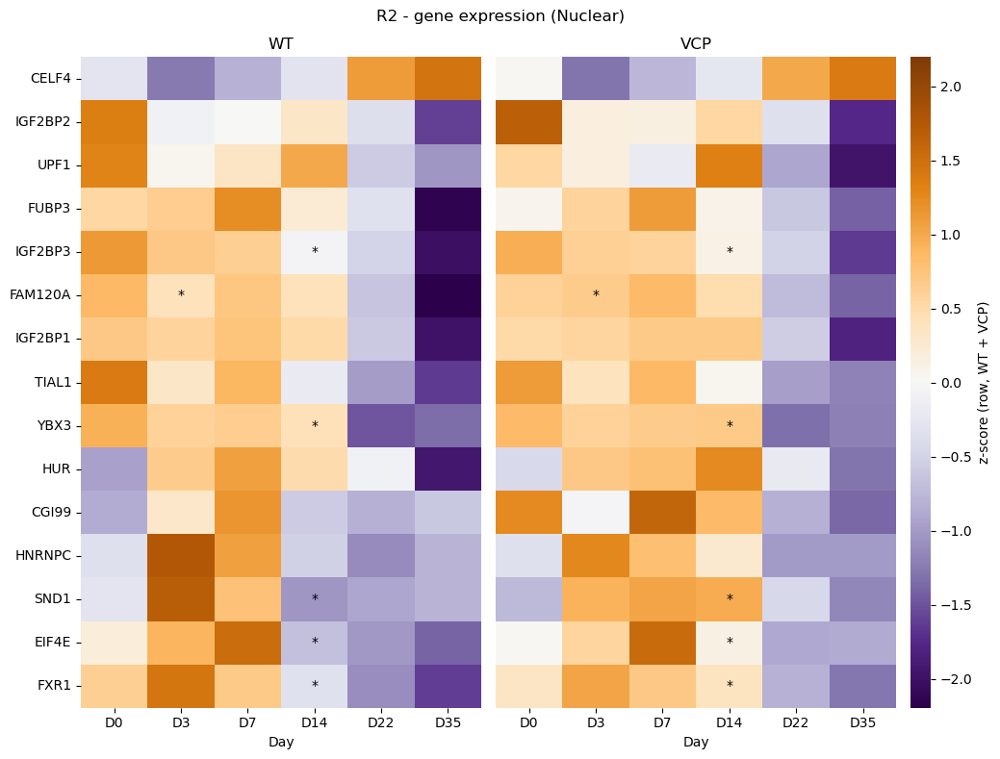

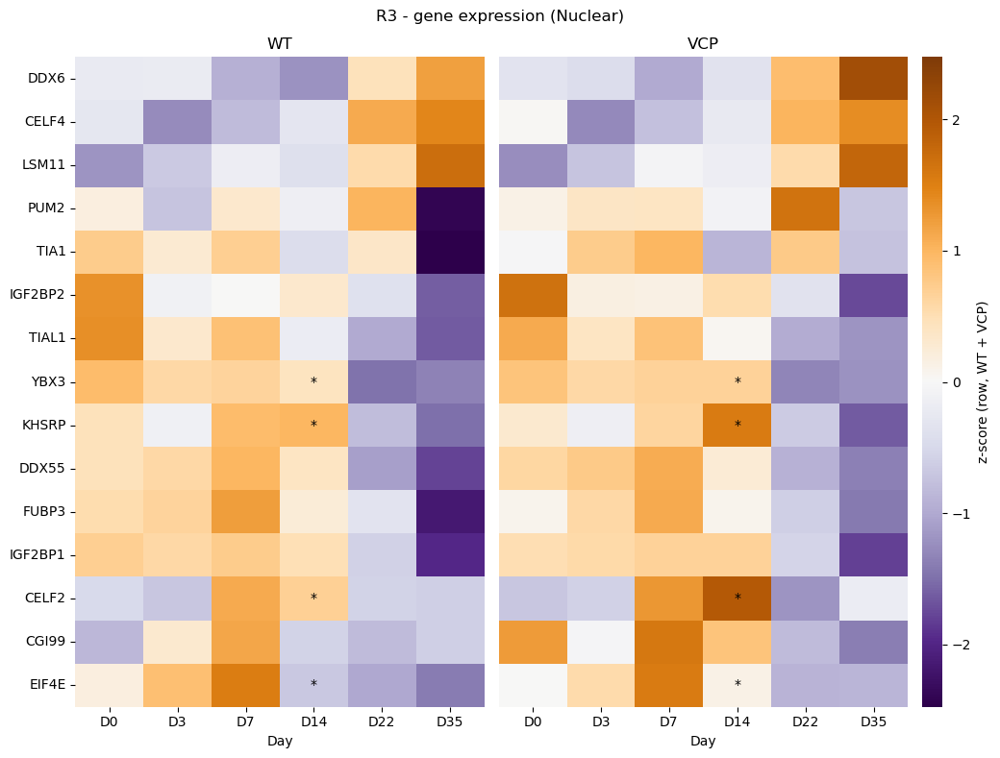

In [22]:
expression_dir = f"{figures_subfolder}/top_regulators_expression_CTRL_vs_VCP"
os.makedirs(expression_dir, exist_ok=True)

for region, genes_list in zip(["R1", "R2", "R3"], [R1_top15_no_mod, R2_top15_no_mod, R3_top15_no_mod]):
    path = f"{expression_dir}/heatmap_gene_expression_Nuclear_top15_{region}_regulators_CTRL_vs_VCP.pdf"
    plot_wt_vs_vcp_heatmap(
        genes_list, f"{region} - gene expression (Nuclear)",
        path,
        df_genes, meta_genes, value_col="log2_expression",
    )
    register_figure(path, legend=f"Nuclear gene expression (log2(normalised counts + 1)) of the top 15 {region} "
                    "regulators over MN differentiation, CTRL (left) vs VCP (right). Mean of replicates per day; each "
                    "row z-scored over the 12 columns (6 days x 2 genotypes), so both panels share one scale. Rows "
                    "clustered on the CTRL panel. * = Welch's t-test CTRL vs VCP on replicates, p < 0.05 (uncorrected).")


  not found: ['DDX55', 'LARP4', 'LSM11']
  no nuclear values over time: ['ZNF622', 'UCHL5']


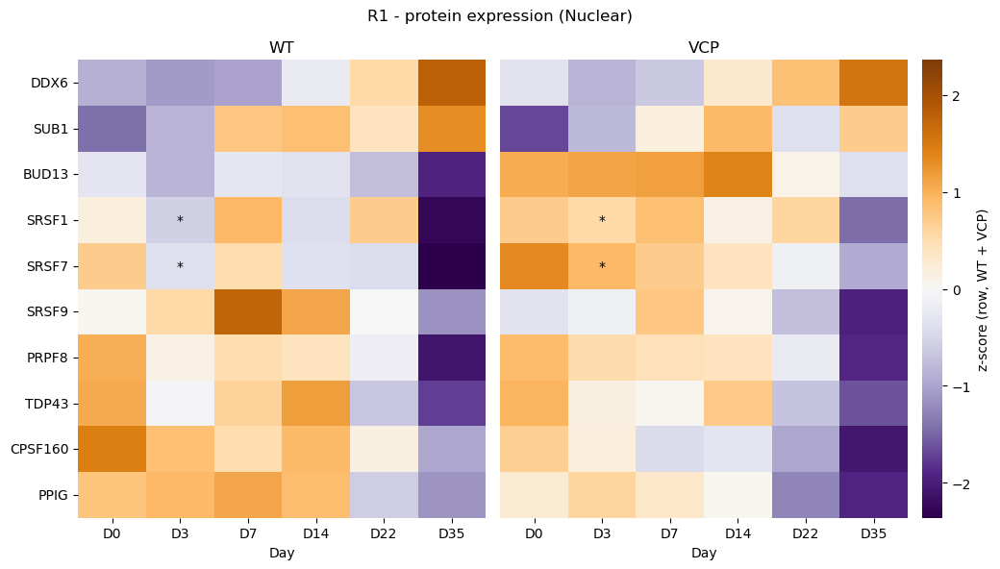

  not found: ['FAM120A', 'CELF4', 'IGF2BP1', 'YBX3', 'CGI99']


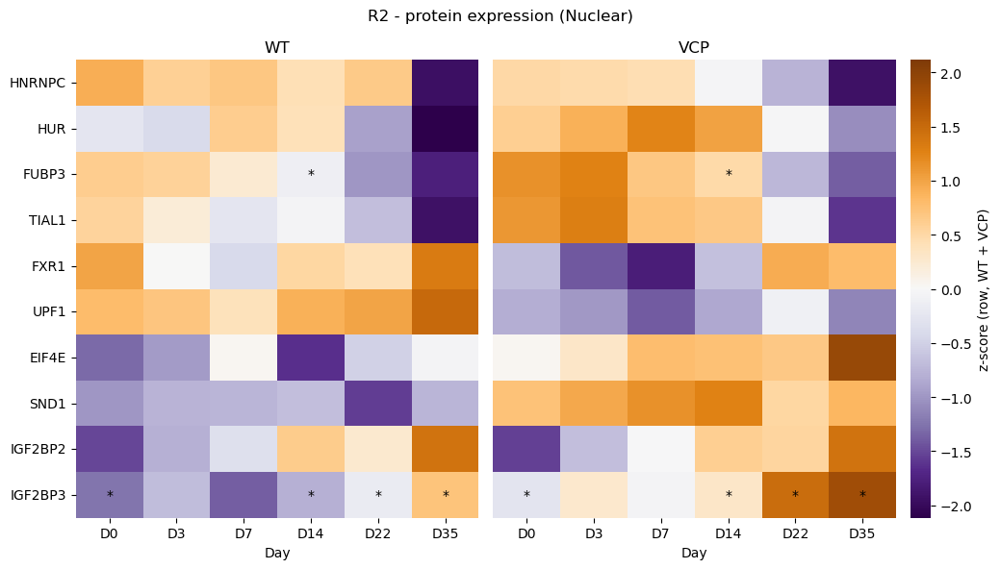

  not found: ['CELF4', 'DDX55', 'CELF2', 'LSM11', 'IGF2BP1', 'YBX3', 'PUM2', 'CGI99']


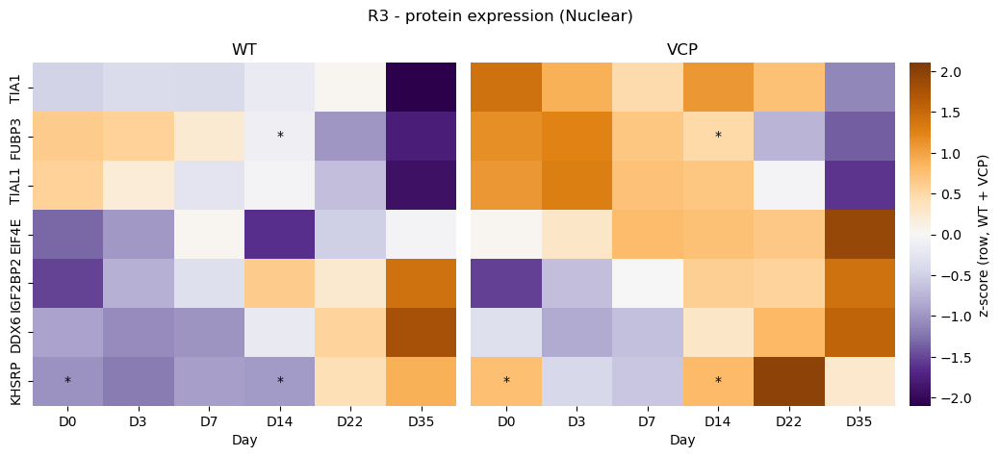

  not found: ['DDX55', 'LARP4', 'LSM11']
  no cytoplasmic values over time: ['ZNF622', 'BUD13', 'SRSF9']


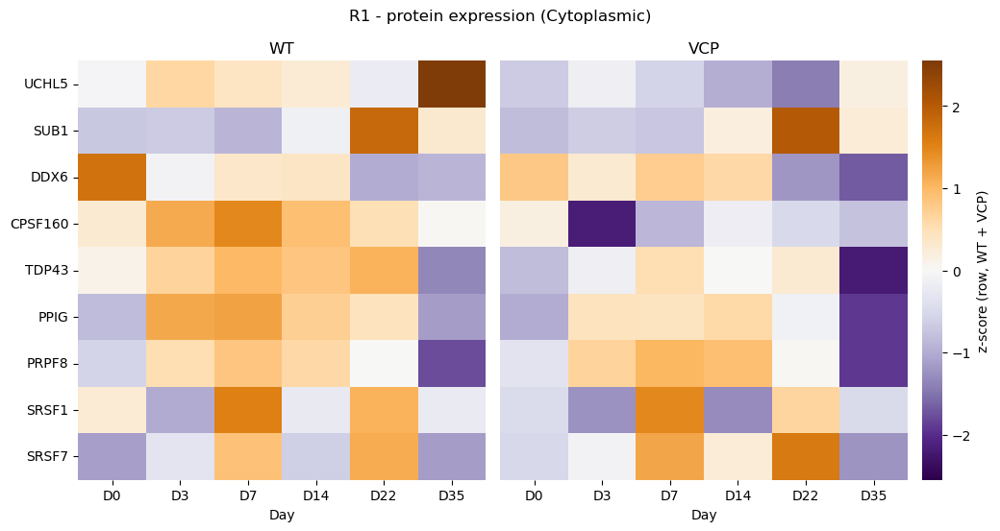

  not found: ['FAM120A', 'CELF4', 'IGF2BP1', 'YBX3', 'CGI99']
  no cytoplasmic values over time: ['TIAL1']


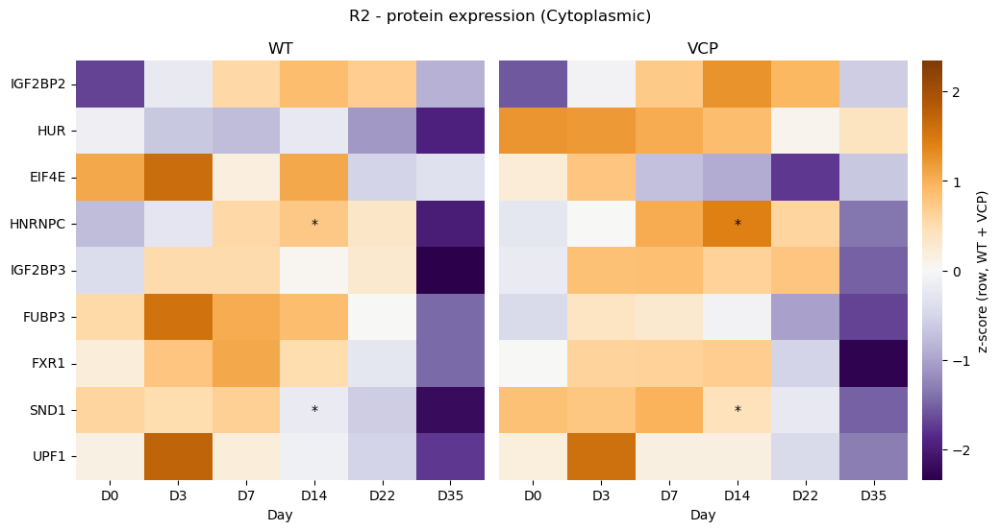

  not found: ['CELF4', 'DDX55', 'CELF2', 'LSM11', 'IGF2BP1', 'YBX3', 'PUM2', 'CGI99']
  no cytoplasmic values over time: ['TIA1', 'TIAL1', 'KHSRP']


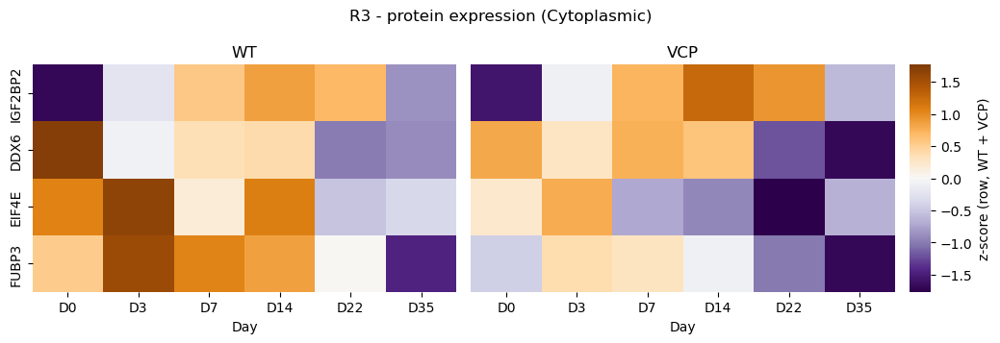

In [23]:
for compartment in ["Nuclear", "Cytoplasmic"]:
    for region, prot_list in zip(["R1", "R2", "R3"], [R1_top15_no_mod, R2_top15_no_mod, R3_top15_no_mod]):
        path = f"{expression_dir}/heatmap_protein_expression_{compartment}_top15_{region}_regulators_CTRL_vs_VCP.pdf"
        plot_wt_vs_vcp_heatmap(
            prot_list, f"{region} - protein expression ({compartment})",
            path,
            df_prot, meta_prot, value_col="expression",   # proteomics is already log2
            compartment=compartment,
        )
        register_figure(path, legend=f"{compartment} protein expression (proteomics GSE152983, log2 median-normalised "
                        f"intensity) of the top 15 {region} regulators over MN differentiation, CTRL (left) vs VCP (right). "
                        "Mean of replicates per day; each row z-scored over the 12 columns (6 days x 2 genotypes). Rows "
                        "clustered on the CTRL panel; grey = not detected. * = Welch's t-test CTRL vs VCP on replicates, "
                        "p < 0.05 (uncorrected).")


  not found: ['AARS', 'PTB-CLIP', 'TROVE2']


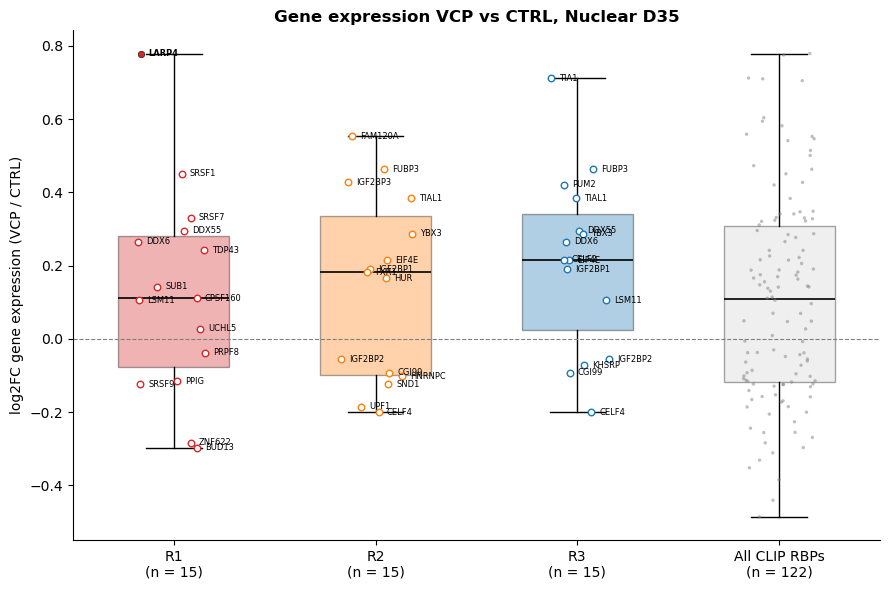

list     RBP  log2FC  pvalue  n_CTRL  n_VCP  significant
  R1   BUD13  -0.297   0.342       4      4        False
  R1  ZNF622  -0.284   0.423       4      4        False
  R1   SRSF9  -0.123   0.129       4      4        False
  R1    PPIG  -0.116   0.864       4      4        False
  R1   PRPF8 -0.0376   0.814       4      4        False
  R1   UCHL5  0.0272   0.891       4      4        False
  R1   LSM11   0.106   0.634       4      4        False
  R1 CPSF160   0.111   0.768       4      4        False
  R1    SUB1   0.142   0.385       4      4        False
  R1   TDP43   0.242   0.139       4      4        False
  R1    DDX6   0.266   0.233       4      4        False
  R1   DDX55   0.296   0.262       4      4        False
  R1   SRSF7    0.33    0.47       4      4        False
  R1   SRSF1   0.451   0.243       4      4        False
  R1   LARP4   0.779 0.00714       4      4         True
  R2   CELF4    -0.2   0.792       4      4        False
  R2    UPF1  -0.186   0.104   

In [24]:
# ---- Differential gene expression VCP vs CTRL at D35 (nuclear), summarised per top-15 list ----
# Per RBP: log2FC = mean VCP - mean CTRL of log2(normalised counts + 1) over replicates,
# p = Welch's t-test on the replicates (uncorrected). Reference box: every RBP with a CLIP dataset.
dge_day, dge_compartment = 35, "Nuclear"

def dge_vcp_vs_ctrl(rbp_list):
    long = expression_long(rbp_list, df_genes, meta_genes, "log2_expression", dge_compartment)
    long = long[long["Day"] == dge_day].dropna(subset=["value"])
    rows = []
    for rbp, sub in long.groupby("RBP", sort=False):
        wt, vcp = sub.loc[sub["Genotype"] == "WT", "value"], sub.loc[sub["Genotype"] == "VCP", "value"]
        p = ttest_ind(vcp, wt, equal_var=False).pvalue if len(wt) > 1 and len(vcp) > 1 else np.nan
        rows.append({"RBP": rbp, "log2FC": vcp.mean() - wt.mean(), "pvalue": p,
                     "n_CTRL": len(wt), "n_VCP": len(vcp)})
    return pd.DataFrame(rows)

all_clip_rbps = sorted({get_RBP_name(c) for c in data_scaled.index} - set(modifs))
dge_lists = {"R1": R1_top15_no_mod, "R2": R2_top15_no_mod, "R3": R3_top15_no_mod, "All CLIP RBPs": all_clip_rbps}
dge = pd.concat({name: dge_vcp_vs_ctrl(rbps) for name, rbps in dge_lists.items()},
                names=["list"]).reset_index(level=0).reset_index(drop=True)
dge["significant"] = dge["pvalue"] < 0.05

list_colors = {"R1": "#d62728", "R2": "#ff7f0e", "R3": "#1f77b4", "All CLIP RBPs": "lightgrey"}
names = list(dge_lists)
fig, ax = plt.subplots(figsize=(9, 6))
data = [dge.loc[dge["list"] == n, "log2FC"].values for n in names]
bp = ax.boxplot(data, positions=range(len(names)), widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": "black", "linewidth": 1.2})
for patch, n in zip(bp["boxes"], names):
    patch.set_facecolor(list_colors[n])
    patch.set_alpha(0.35)
rng = np.random.default_rng(0)
for i, n in enumerate(names):
    sub = dge[dge["list"] == n]
    x = i + rng.uniform(-0.18, 0.18, len(sub))
    if n == "All CLIP RBPs":   # background: small grey dots, no labels
        ax.scatter(x, sub["log2FC"], s=6, color="grey", alpha=0.5, edgecolors="none", zorder=3)
        continue
    sig = sub["significant"].values
    ax.scatter(x[~sig], sub["log2FC"][~sig], s=22, facecolors="white", edgecolors=list_colors[n], zorder=3)
    ax.scatter(x[sig], sub["log2FC"][sig], s=22, color=list_colors[n], edgecolors="black", linewidths=0.4, zorder=4)
    for xi, (_, row) in zip(x, sub.iterrows()):
        ax.text(xi + 0.04, row["log2FC"], row["RBP"], fontsize=6, va="center",
                weight="bold" if row["significant"] else "normal")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.set_xticks(range(len(names)))
ax.set_xticklabels([f"{n}\n(n = {len(d)})" for n, d in zip(names, data)])
ax.set_ylabel("log2FC gene expression (VCP / CTRL)")
ax.set_title(f"Gene expression VCP vs CTRL, {dge_compartment} D{dge_day}", weight="bold")
sns.despine(ax=ax)
plt.tight_layout()
save_figure(f"{expression_dir}/boxplot_log2FC_gene_expression_{dge_compartment}_D{dge_day}_top15_regulators_VCP_vs_CTRL.pdf",
            legend=f"Differential gene expression VCP vs CTRL in the nuclear fraction at D{dge_day} for the top 15 "
                   "regulators of R1, R2 and R3 (RNA modifications excluded), and for every RBP with a CLIP dataset "
                   "(grey, reference). log2FC = mean VCP - mean CTRL of log2(normalised counts + 1) over replicates "
                   "(VCP-R155C and VCP-R191Q pooled). Filled dots, bold names: Welch's t-test VCP vs CTRL on "
                   "replicates, p < 0.05 (uncorrected). Boxes: median and IQR, whiskers 1.5 x IQR.")
plt.show()

print(dge[dge["list"] != "All CLIP RBPs"].sort_values(["list", "log2FC"]).to_string(index=False, float_format="%.3g"))


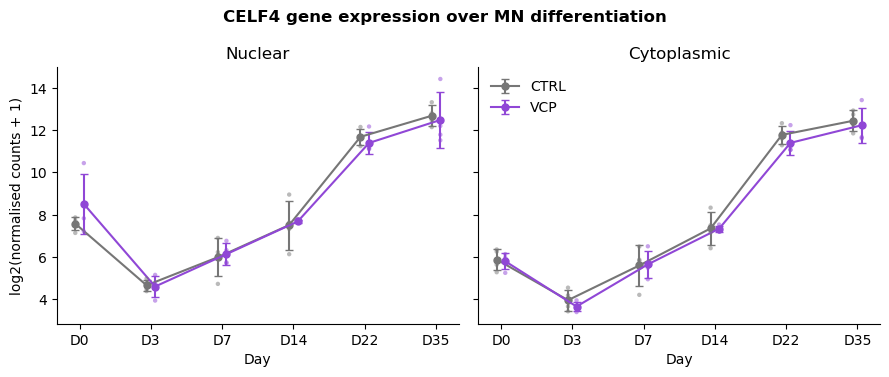

In [25]:
# ---- CELF4 gene expression over time, CTRL vs VCP (mean +/- SD of replicates) ----
gene_focus = "CELF4"
genotype_colors = {"WT": "#767676", "VCP": "#9047d6"}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, compartment in zip(axes, ["Nuclear", "Cytoplasmic"]):
    long = expression_long([gene_focus], df_genes, meta_genes, "log2_expression", compartment).dropna(subset=["value"])
    for k, (genotype, color) in enumerate(genotype_colors.items()):
        sub = long[long["Genotype"] == genotype]
        stats_day = sub.groupby("Day")["value"].agg(["mean", "std"]).reindex(DAY_ORDER)
        x = np.arange(len(DAY_ORDER)) + (k - 0.5) * 0.12   # small offset so the error bars do not overlap
        ax.errorbar(x, stats_day["mean"], yerr=stats_day["std"], color=color, marker="o", markersize=5,
                    capsize=3, linewidth=1.5, label="CTRL" if genotype == "WT" else genotype)
        day_pos = dict(zip(DAY_ORDER, x))
        ax.scatter(sub["Day"].map(day_pos), sub["value"], s=10, color=color, alpha=0.5, edgecolors="none", zorder=3)
    for j, day in enumerate(DAY_ORDER):
        day_vals = long[long["Day"] == day]
        wt = day_vals.loc[day_vals["Genotype"] == "WT", "value"]
        vcp = day_vals.loc[day_vals["Genotype"] == "VCP", "value"]
        if len(wt) > 1 and len(vcp) > 1 and ttest_ind(wt, vcp, equal_var=False).pvalue < 0.05:
            ax.text(j, day_vals["value"].max(), "*", ha="center", va="bottom", fontsize=14)
    ax.set_xticks(range(len(DAY_ORDER)))
    ax.set_xticklabels([f"D{d}" for d in DAY_ORDER])
    ax.set_xlabel("Day")
    ax.set_title(compartment)
    sns.despine(ax=ax)
axes[0].set_ylabel("log2(normalised counts + 1)")
axes[-1].legend(frameon=False)
fig.suptitle(f"{gene_focus} gene expression over MN differentiation", weight="bold")
plt.tight_layout()
save_figure(f"{expression_dir}/lineplot_gene_expression_{gene_focus}_over_time_CTRL_vs_VCP.pdf",
            legend=f"{gene_focus} gene expression (log2(normalised counts + 1)) over MN differentiation (D0 -> D35) "
                   "in the nuclear (left) and cytoplasmic (right) fractions, CTRL (grey) vs VCP (purple; R155C and "
                   "R191Q pooled). Mean +/- SD of replicates; dots = individual replicates. * = Welch's t-test "
                   "CTRL vs VCP on replicates, p < 0.05 (uncorrected).")
plt.show()


<a id="d22-d35-zscore"></a>
## Change in regulator activity between D22 and D35

For each region, the change in Nuclear WT score (D35 − D22) of every regulator is z-scored against the distribution of changes across **all** regulators. The p-values are one-sided (normal survival function), in the direction set by `region_configs`: a **decrease** for Region 1 (sign −1) and an **increase** for Regions 2 and 3 (sign +1). The scores come from the unscaled region matrices, with R2 positive, i.e. depletion strength.

<a id="d22-d35-all"></a>
### All regulators

Bubble plot of every regulator that is significant (p < 0.05) in at least one region. Rows are grouped by significance pattern (R1 only, R2 only, …, all) and sorted by mean signed z within each group. Colour = raw z-score, size = −log10(p), grey dot = not significant. This figure is not saved (the `savefig` lines are commented out).

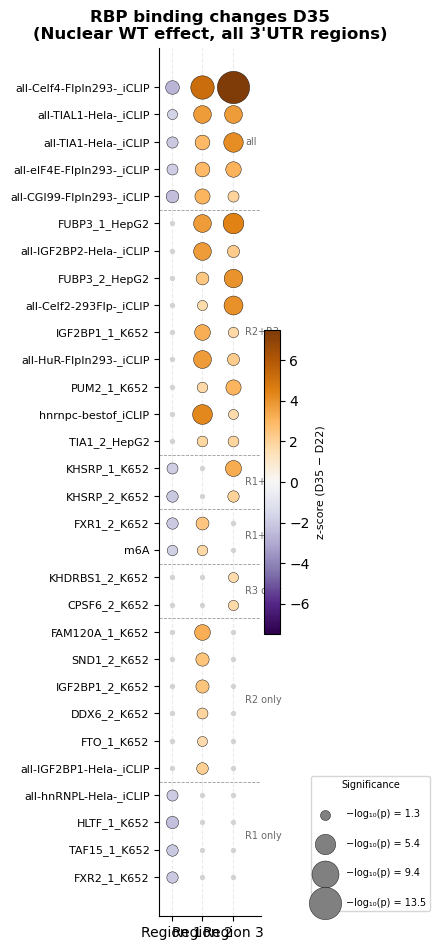

In [26]:
from scipy import stats
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np


matrix_merged_unscaled = pd.concat([matrix_region1, matrix_region2, matrix_region3], axis=1)

region_configs = {
    'Region 1': ('Nuclear_WT_D22_region1', 'Nuclear_WT_D35_region1', -1),
    'Region 2': ('Nuclear_WT_D22_region2', 'Nuclear_WT_D35_region2',+1),
    'Region 3': ('Nuclear_WT_D22_region3', 'Nuclear_WT_D35_region3', +1),
}

summaries = {}
for label, (col_d22, col_d35, sign) in region_configs.items():
    diff = matrix_merged_unscaled[col_d35] - matrix_merged_unscaled[col_d22]
    z = (diff - diff.mean()) / diff.std(ddof=0)
    signal_z = sign * z
    raw_z    = z
    p = stats.norm.sf(signal_z)
    summaries[label] = pd.DataFrame({'signal_z': signal_z, 'raw_z': raw_z, 'pvalue': p})

sig_rbps = set()
for df in summaries.values():
    sig_rbps.update(df[df['pvalue'] < 0.05].index)
sig_rbps = sorted(sig_rbps)

z_mat    = pd.DataFrame({r: summaries[r]['raw_z']    for r in summaries}).loc[sig_rbps]
sig_z_mat= pd.DataFrame({r: summaries[r]['signal_z'] for r in summaries}).loc[sig_rbps]
p_mat    = pd.DataFrame({r: summaries[r]['pvalue']   for r in summaries}).loc[sig_rbps]
nlp_mat  = -np.log10(p_mat)

# ── Sort by significance pattern ─────────────────────────────────────────────
sig_flag = (p_mat < 0.05)
regions  = list(sig_flag.columns)   # ['Region 1', 'Region 2', 'Region 3']

_pattern_order = [
    ((True,  False, False), 'R1 only'),
    ((False, True,  False), 'R2 only'),
    ((False, False, True),  'R3 only'),
    ((True,  True,  False), 'R1+R2'),
    ((True,  False, True),  'R1+R3'),
    ((False, True,  True),  'R2+R3'),
    ((True,  True,  True),  'all'),
]

ordered_rbps = []
group_info   = []   # (start_i, end_i, label)

for pattern, glabel in _pattern_order:
    group = [
        rbp for rbp in sig_flag.index
        if tuple(sig_flag.loc[rbp, r] for r in regions) == pattern
    ]
    if not group:
        continue
    # within-group sort by mean signal_z ascending
    group.sort(key=lambda rbp: sig_z_mat.loc[rbp].mean())
    start = len(ordered_rbps)
    ordered_rbps.extend(group)
    group_info.append((start, len(ordered_rbps) - 1, glabel))

sort_order = pd.Index(ordered_rbps)
z_mat   = z_mat.loc[sort_order]
p_mat   = p_mat.loc[sort_order]
nlp_mat = nlp_mat.loc[sort_order]

n_rbps        = len(ordered_rbps)
col_positions = [i * 2 for i in range(len(regions))]

# ── Bubble plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, max(4, n_rbps * 0.32)))

cmap   = cm.RdBu_r
cmap = sns.diverging_palette(250, 30, s=80, l=55, as_cmap=True)
cmap = cm.PuOr_r
absmax = max(abs(z_mat.values.max()), abs(z_mat.values.min()), 2)
norm_c = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

for j, region in enumerate(regions):
    xpos = col_positions[j]
    for i, rbp in enumerate(z_mat.index):
        z_val   = z_mat.loc[rbp, region]
        p_val   = p_mat.loc[rbp, region]
        nlp_val = nlp_mat.loc[rbp, region]
        if p_val < 0.05:
            ax.scatter(xpos, i, s=nlp_val * 40, c=[cmap(norm_c(z_val))],
                       zorder=3, edgecolors='black', linewidths=0.3)
        else:
            ax.scatter(xpos, i, s=8, c='lightgrey', zorder=2)

# Group separators and labels
for idx, (start, end, glabel) in enumerate(group_info):
    if idx > 0:
        ax.axhline(start - 0.5, color='black', linewidth=0.6, linestyle='--', alpha=0.4)
    ymid = (start + end) / 2
    ax.text(col_positions[-1] + 0.8, ymid, glabel, fontsize=7, va='center', color='dimgrey')

ax.set_xticks(col_positions)
ax.set_xticklabels(regions, fontsize=10)
ax.set_yticks(range(n_rbps))
ax.set_yticklabels(z_mat.index, fontsize=8)
ax.set_xlim(-0.8, col_positions[-1] + 1.8)
ax.grid(axis='x', alpha=0.25, linestyle='--')
ax.set_title("RBP binding changes D35\n(Nuclear WT effect, all 3'UTR regions)", weight='bold')

sm = cm.ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.35, pad=0.03)
cbar.set_label('z-score (D35 − D22)', fontsize=8)

nlp_max = nlp_mat[p_mat < 0.05].max().max()
legend_values = np.linspace(-np.log10(0.05), nlp_max, 4)
legend_handles = [
    plt.scatter([], [], s=nlp_ex * 40, c='grey', edgecolors='black', linewidths=0.3,
                label=f'−log₁₀(p) = {nlp_ex:.1f}')
    for nlp_ex in legend_values
]
ax.legend(handles=legend_handles, title='Significance', fontsize=7, title_fontsize=7,
          loc='lower left', bbox_to_anchor=(1.45, 0),
          labelspacing=2, handletextpad=1.2)

sns.despine(ax=ax)
plt.tight_layout()

# save_figure(f"{figures_subfolder}/top_regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_all_regulators.pdf", legend="...")
plt.show()

<a id="d22-d35-top"></a>
### Top regulators only

Same z-scores (still computed against all regulators), shown only for the top-15 CLIPs of R1, R2 and R3 (`R*_top15_long_names`). Rows are grouped by the top-15 list(s) each CLIP belongs to (R1, R2, R3, R1+R2, …), in top-15 rank order. Saved as `top_regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_top15_regulators.pdf`.

This cell also defines `matrix_merged_grouped` (all regulators × all conditions and regions, ±inf → NaN), `ordered_regs`, `group_of` and `reg_group_info`. The heatmaps and correlations below reuse them.

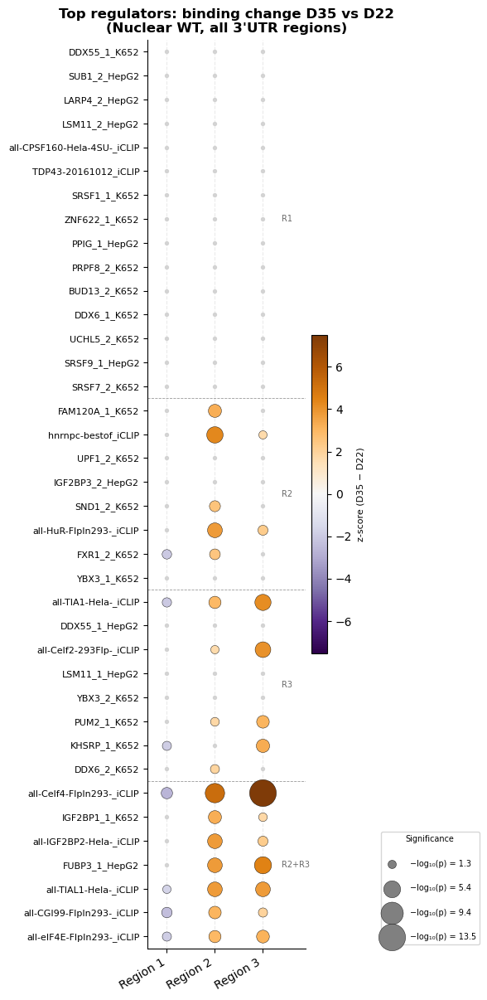

In [27]:
# ---- D35 − D22 z-score bubble plot, restricted to the top-15 regulators of R1 / R2 / R3 ----
# Same z-scoring as above (each regulator's D35 − D22 change is compared with the
# distribution of changes across ALL regulators), but at the RBP_name level
# (replicates averaged) on which R*_top15_long_names were picked.
regulator_sets = {"R1": R1_top15_long_names, "R2": R2_top15_long_names, "R3": R3_top15_long_names}

matrix_merged_grouped = matrix_merged_unscaled.replace([np.inf, -np.inf], np.nan)
# matrix_merged_grouped = matrix_merged_grouped.groupby(matrix_merged_grouped.index.map(get_clip_name)).mean()

summaries_reg = {}
for label, (col_d22, col_d35, sign) in region_configs.items():
    diff = matrix_merged_grouped[col_d35] - matrix_merged_grouped[col_d22]
    z = (diff - diff.mean()) / diff.std(ddof=0)
    summaries_reg[label] = pd.DataFrame({'signal_z': sign * z, 'raw_z': z, 'pvalue': stats.norm.sf(sign * z)})

# ── Group regulators by which top-15 list(s) they belong to ──────────────────
membership = {}
for set_label, regs in regulator_sets.items():
    for reg in regs:
        membership.setdefault(reg, []).append(set_label)
missing = [reg for reg in membership if reg not in matrix_merged_grouped.index]
if missing:
    print(f"Not found in matrix_merged_grouped: {missing}")
group_of = {reg: "+".join(sets) for reg, sets in membership.items() if reg not in missing}

group_order = sorted(set(group_of.values()),
                     key=lambda g: (g.count("+"), [list(regulator_sets).index(s) for s in g.split("+")]))

ordered_regs = []
reg_group_info = []   # (start_i, end_i, label)
for glabel in group_order:
    group = [reg for reg in group_of if group_of[reg] == glabel]   # keeps top-15 rank order
    start = len(ordered_regs)
    ordered_regs.extend(group)
    reg_group_info.append((start, len(ordered_regs) - 1, glabel))

z_mat_reg   = pd.DataFrame({r: summaries_reg[r]['raw_z']  for r in summaries_reg}).loc[ordered_regs]
p_mat_reg   = pd.DataFrame({r: summaries_reg[r]['pvalue'] for r in summaries_reg}).loc[ordered_regs]
nlp_mat_reg = -np.log10(p_mat_reg)

regions       = list(z_mat_reg.columns)
n_regs        = len(ordered_regs)
col_positions = [i * 2 for i in range(len(regions))]

# ── Bubble plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.5, max(4, n_regs * 0.32)))

cmap   = cm.PuOr_r
absmax = max(np.nanmax(np.abs(z_mat_reg.values)), 2)
norm_c = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

for j, region in enumerate(regions):
    xpos = col_positions[j]
    for i, reg in enumerate(ordered_regs):
        z_val   = z_mat_reg.loc[reg, region]
        p_val   = p_mat_reg.loc[reg, region]
        nlp_val = nlp_mat_reg.loc[reg, region]
        if p_val < 0.05:
            ax.scatter(xpos, i, s=nlp_val * 40, c=[cmap(norm_c(z_val))],
                       zorder=3, edgecolors='black', linewidths=0.3)
        else:
            ax.scatter(xpos, i, s=8, c='lightgrey', zorder=2)

for idx, (start, end, glabel) in enumerate(reg_group_info):
    if idx > 0:
        ax.axhline(start - 0.5, color='black', linewidth=0.6, linestyle='--', alpha=0.4)
    ax.text(col_positions[-1] + 0.8, (start + end) / 2, glabel, fontsize=7, va='center', color='dimgrey')

ax.set_xticks(col_positions)
ax.set_xticklabels(regions, fontsize=10, rotation=30, ha='right')
ax.set_yticks(range(n_regs))
ax.set_yticklabels(ordered_regs, fontsize=8)
ax.set_ylim(n_regs - 0.5, -0.5)
ax.set_xlim(-0.8, col_positions[-1] + 1.8)
ax.grid(axis='x', alpha=0.25, linestyle='--')
ax.set_title("Top regulators: binding change D35 vs D22\n(Nuclear WT, all 3'UTR regions)", weight='bold')

sm = cm.ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.35, pad=0.03)
cbar.set_label('z-score (D35 − D22)', fontsize=8)

nlp_sig = nlp_mat_reg[p_mat_reg < 0.05]
if nlp_sig.notna().any().any():
    legend_values = np.linspace(-np.log10(0.05), np.nanmax(nlp_sig.values), 4)
    legend_handles = [
        plt.scatter([], [], s=nlp_ex * 40, c='grey', edgecolors='black', linewidths=0.3,
                    label=f'−log₁₀(p) = {nlp_ex:.1f}')
        for nlp_ex in legend_values
    ]
    ax.legend(handles=legend_handles, title='Significance', fontsize=7, title_fontsize=7,
              loc='lower left', bbox_to_anchor=(1.45, 0), labelspacing=2, handletextpad=1.2)

sns.despine(ax=ax)
plt.tight_layout()

save_figure(f"{figures_subfolder}/top_regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_top15_regulators.pdf",
            legend="Change in Welch score between D22 and D35 (D35 - D22, nuclear fraction, CTRL) of the top-15 "
                   "regulators of R1, R2 and R3 (rows, grouped by the top-15 list(s) they belong to), in each region "
                   "(columns; R2 score = depletion strength, positive). Each change is z-scored against the changes of "
                   "all regulators in that region. Colour = z-score; bubble size = -log10(p), one-sided normal p in "
                   "the direction tested for lengthening (decrease for R1, increase for R2 and R3); grey dot = p >= 0.05.")
plt.show()


<a id="welch-over-time"></a>
## Welch score of the top regulators over time (Nuclear WT)

Heatmap of the top regulators (rows, same order and groups as above) × days, one block per region. Each region is z-scored **as a whole**, with a single mean and SD over all regulators × all days of that region. Values can therefore be compared across days and across regulators, but not across regions, whose scales differ about 10-fold. When an RBP has several CLIP datasets, the cell line (and replicate) is added to its label. NaN cells are grey. Saved as `top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_zscore_per_region.pdf`.

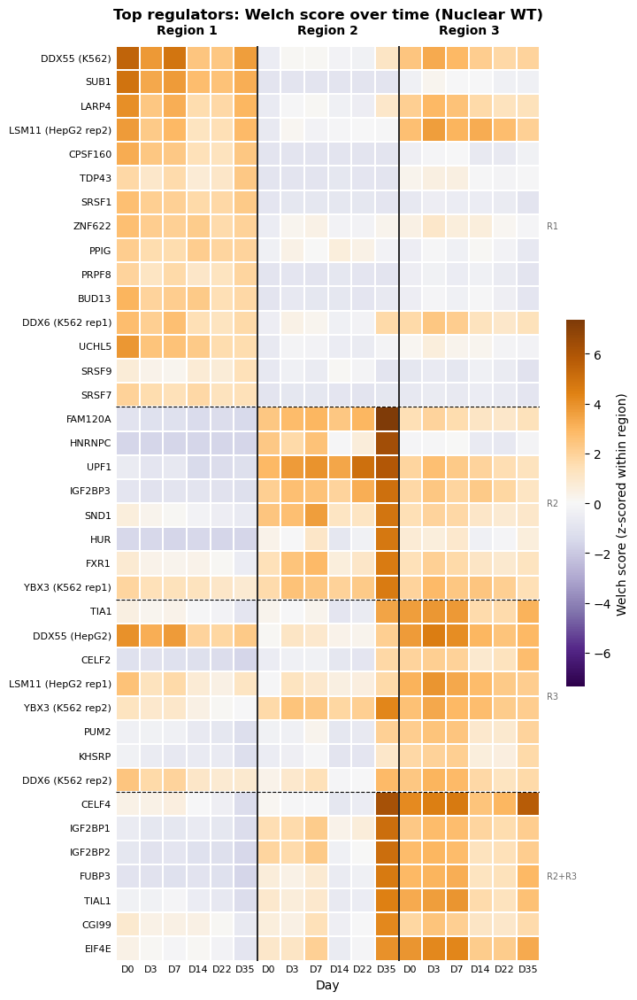

In [28]:
# ---- Welch score of the top regulators across days and regions (Nuclear WT), row-normalised ----
# Scores are oriented so that higher = stronger effect in every region
# (R1: proximal enrichment, R2: proximal depletion, R3: distal enrichment).
# Standardised WITHIN each region, with a single mean/std computed over all
# regulators x all days of that region: values stay comparable across days (time
# evolution) and across RBPs, but not across regions (whose scales differ ~10x).
days = ["D0", "D3", "D7", "D14", "D22", "D35"]
region_ids = [1, 2, 3]
heat_cols = [f"Nuclear_WT_{day}_region{r}" for r in region_ids for day in days]

missing_cols = [c for c in heat_cols if c not in matrix_merged_grouped.columns]
if missing_cols:
    print(f"Missing columns (left blank): {missing_cols}")

heat_all = matrix_merged_grouped.reindex(columns=heat_cols)
for r in region_ids:
    block = [c for c in heat_cols if c.endswith(f"_region{r}")]
    vals = heat_all[block].stack()
    heat_all[block] = (heat_all[block] - vals.mean()) / vals.std()

heat_norm = heat_all.loc[ordered_regs]

# RBP names as tick labels; CLIPs sharing an RBP name get their cell line appended
# (plus the replicate when the cell line is shared too). ENCODE names: RBP_rep_cellline
def clip_tick_labels(clip_names):
    short = [get_RBP_name(c) for c in clip_names]
    labels = []
    for c, s in zip(clip_names, short):
        parts = c.split("_")
        if short.count(s) == 1 or len(parts) != 3:
            labels.append(s if short.count(s) == 1 else c)
            continue
        cell_line = parts[2].replace("K652", "K562")
        n_same_line = sum(so == s and o.split("_")[-1] == parts[2] for o, so in zip(clip_names, short))
        labels.append(f"{s} ({cell_line} rep{parts[1]})" if n_same_line > 1 else f"{s} ({cell_line})")
    return labels

reg_tick_label = dict(zip(ordered_regs, clip_tick_labels(ordered_regs)))

fig, ax = plt.subplots(figsize=(7.5, max(4, n_regs * 0.3)))
absmax = np.nanmax(np.abs(heat_norm.values))
sns.heatmap(heat_norm, cmap=cm.PuOr_r, center=0, vmin=-absmax, vmax=absmax,
            xticklabels=days * len(region_ids), yticklabels=[reg_tick_label[r] for r in ordered_regs],
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Welch score (z-scored within region)", "shrink": 0.4}, ax=ax)
ax.set_facecolor("lightgrey")   # NaN cells

# Region separators (vertical) and region labels on top
for k in range(1, len(region_ids)):
    ax.axvline(k * len(days), color="black", linewidth=1.2)
for k, r in enumerate(region_ids):
    ax.text(k * len(days) + len(days) / 2, -0.4, f"Region {r}",
            ha="center", va="bottom", fontsize=10, weight="bold")

# Regulator-group separators (horizontal) and labels on the right
for idx, (start, end, glabel) in enumerate(reg_group_info):
    if idx > 0:
        ax.axhline(start, color="black", linewidth=0.8, linestyle="--")
    ax.text(len(heat_cols) + 0.3, (start + end + 1) / 2, glabel,
            fontsize=7, va="center", color="dimgrey")

ax.set_xlabel("Day")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8, length=0)
ax.tick_params(axis="x", labelsize=8, rotation=0, length=0)
ax.set_title("Top regulators: Welch score over time (Nuclear WT)", weight="bold", pad=22)
plt.tight_layout()

save_figure(f"{figures_subfolder}/top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_zscore_per_region.pdf",
            legend="Welch score over MN differentiation (D0 -> D35, nuclear fraction, CTRL) of the top-15 regulators of R1, R2 and R3 (rows, grouped by the top-15 list(s) they belong to), one block of 6 days per region (R2 score = depletion strength, positive). "
                   "Each region z-scored as a whole (one mean and SD over all regulators x days of that region): "
                   "comparable across days and regulators, not across regions. When an RBP has several CLIP datasets, "
                   "the cell line (and replicate) is added to its name. Grey = missing.")
plt.show()


<a id="welch-over-time-split"></a>
### One heatmap per regulator set

Same values as above, split into three panels, one per top-15 list (R1, R2, R3), with a shared colour scale. Each panel still shows the three regions. Saved as `top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_split_by_list.pdf`. The next cell shows the same values as boxplots (one box per region × day over the regulators of each list), saved as `top_regulators_activity_over_time/boxplot_welch_score_over_time_NuclearWT_top15_regulators_split_by_list.pdf`.

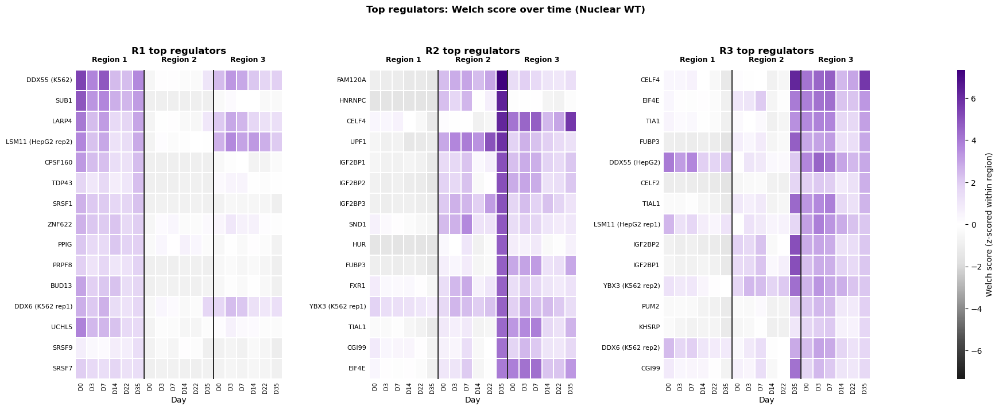

In [29]:
# ---- Same Welch z-scores, one heatmap per regulator set (R1 / R2 / R3 top-15) ----
# Each panel shows the top-15 regulators of one region (top-15 rank order) across
# the 3 regions x days. Uses heat_all (z-scored within region) from the cell above,
# with a single colour scale shared by the 3 panels.
set_labels = list(regulator_sets)
panel_mats = {s: heat_all.loc[[r for r in regulator_sets[s] if r in heat_all.index]] for s in set_labels}
absmax = max(np.nanmax(np.abs(m.values)) for m in panel_mats.values())

import seaborn as sns

from matplotlib.colors import LinearSegmentedColormap

GrPu = LinearSegmentedColormap.from_list(
    "GrPu",
    [
        "#1a1a1a",  # dark gray
        "#4d4d4d",
        "#999999",
        "#e0e0e0",
        "#ffffff",  # white center
        "#e4d4f4",
        "#b388dd",
        "#7b3fb0",
        "#3f007d",  # deep purple
    ],
)
GrPu_r = GrPu.reversed()

fig, axes = plt.subplots(1, len(set_labels) + 1, figsize=(20, 7),
                         gridspec_kw={"width_ratios": [1] * len(set_labels) + [0.04], "wspace": 0.55})
for ax, s in zip(axes[:-1], set_labels):
    mat = panel_mats[s]
    sns.heatmap(mat, cmap=GrPu, center=0, vmin=-absmax, vmax=absmax,
                xticklabels=days * len(region_ids), yticklabels=[reg_tick_label[r] for r in mat.index],
                linewidths=0.3, linecolor="white", cbar=ax is axes[-2], cbar_ax=axes[-1] if ax is axes[-2] else None,
                cbar_kws={"label": "Welch score (z-scored within region)"}, ax=ax)
    ax.set_facecolor("lightgrey")   # NaN cells
    for k in range(1, len(region_ids)):
        ax.axvline(k * len(days), color="black", linewidth=1.2)
    for k, r in enumerate(region_ids):
        ax.text(k * len(days) + len(days) / 2, -0.3, f"Region {r}",
                ha="center", va="bottom", fontsize=9, weight="bold")
    ax.set_title(f"{s} top regulators", weight="bold", pad=20)
    ax.set_xlabel("Day")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8, length=0)
    ax.tick_params(axis="x", labelsize=7, rotation=90, length=0)

fig.suptitle("Top regulators: Welch score over time (Nuclear WT)", weight="bold", y=1.04)
save_figure(f"{figures_subfolder}/top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_split_by_list.pdf",
            legend="Same values as heatmap_welch_score_over_time_NuclearWT_top15_regulators_zscore_per_region.pdf "
                   "(each region z-scored as a whole), split into one panel per top-15 list (R1, R2, R3 regulators), "
                   "each showing the 3 regions x 6 days (D0 -> D35, nuclear CTRL), with a shared colour scale. Grey = missing.")
plt.show()


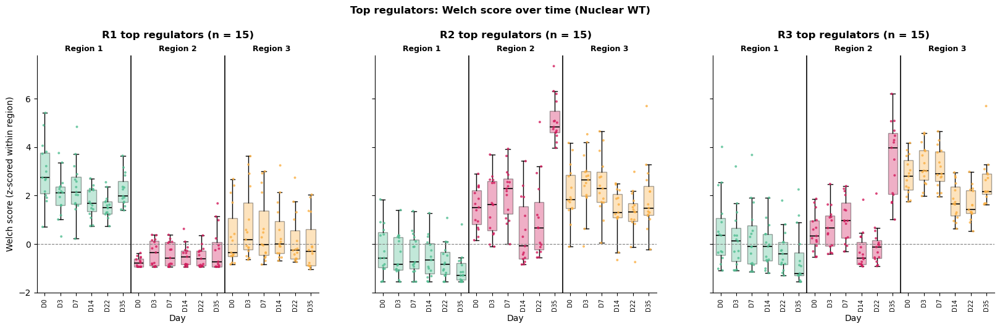

In [30]:
# ---- Same Welch z-scores as the split heatmap, summarised as boxplots ----
# One panel per regulator set (R1 / R2 / R3 top-15); each box = the regulators of
# that set at one region x day (heat_all, z-scored within region). Shared y axis.
region_colors = {1: "#51be92", 2: "#d31c5d", 3: "#faaf43"}

fig, axes = plt.subplots(1, len(set_labels), figsize=(20, 5), sharey=True)
for ax, s in zip(axes, set_labels):
    mat = panel_mats[s]
    positions = np.arange(len(heat_cols))
    data = [mat[c].dropna().values for c in heat_cols]
    col_colors = [region_colors[int(c.split("region")[-1])] for c in heat_cols]
    bp = ax.boxplot(data, positions=positions, widths=0.6, patch_artist=True,
                    showfliers=False, medianprops={"color": "black", "linewidth": 1.2})
    for patch, color in zip(bp["boxes"], col_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.35)
    rng = np.random.default_rng(0)
    for x, vals, color in zip(positions, data, col_colors):
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(vals)), vals, s=8, color=color,
                   edgecolors="none", alpha=0.8, zorder=3)
    ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
    for k in range(1, len(region_ids)):
        ax.axvline(k * len(days) - 0.5, color="black", linewidth=1.2)
    for k, r in enumerate(region_ids):
        ax.text(k * len(days) + (len(days) - 1) / 2, 1.01, f"Region {r}", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9, weight="bold")
    ax.set_xticks(positions)
    ax.set_xticklabels(days * len(region_ids), rotation=90, fontsize=7)
    ax.set_xlim(-0.5, len(heat_cols) - 0.5)
    ax.set_title(f"{s} top regulators (n = {len(mat)})", weight="bold", pad=20)
    ax.set_xlabel("Day")
    sns.despine(ax=ax)
axes[0].set_ylabel("Welch score (z-scored within region)")

fig.suptitle("Top regulators: Welch score over time (Nuclear WT)", weight="bold", y=1.04)
save_figure(f"{figures_subfolder}/top_regulators_activity_over_time/boxplot_welch_score_over_time_NuclearWT_top15_regulators_split_by_list.pdf",
            legend="Boxplot version of heatmap_welch_score_over_time_NuclearWT_top15_regulators_split_by_list.pdf: "
                   "same values (each region z-scored as a whole), one panel per top-15 list (R1, R2, R3 regulators). "
                   "Each box = the regulators of that list at one region x day (D0 -> D35, nuclear CTRL; R1 red, "
                   "R2 orange, R3 blue); dots = individual regulators, missing values dropped. Boxes: median and IQR, "
                   "whiskers 1.5 x IQR. Shared y axis; dashed line = 0 (region mean).")
plt.show()


<a id="welch-over-time-row"></a>
### Row z-score within each region (timing of the peak)

Each regulator × region block is z-scored on its own six days. This shows *when* each regulator peaks in each region, independently of its magnitude. Saved as `top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_row_zscore.pdf`.

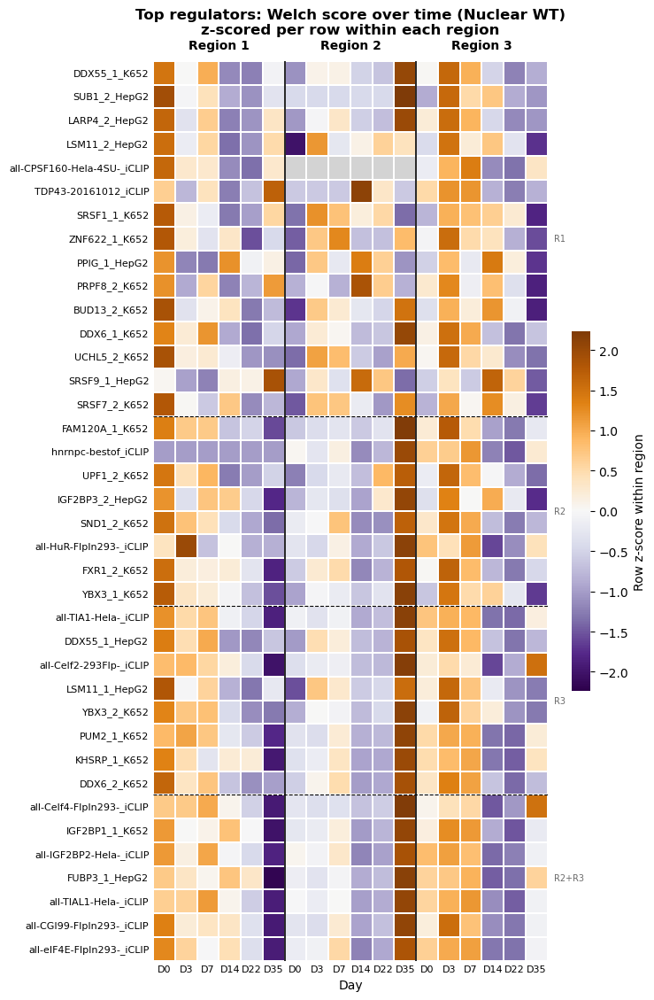

In [31]:
# ---- Same heatmap, z-scored per row WITHIN each region (across the 6 days) ----
# Each regulator x region block is centred/scaled on its own mean/std over time:
# shows WHEN each regulator peaks in each region, independently of its magnitude
# (magnitudes across RBPs are compared in the heatmap above).
heat_norm_row = heat_all.loc[ordered_regs].copy()
for r in region_ids:
    block = [c for c in heat_cols if c.endswith(f"_region{r}")]
    vals = heat_norm_row[block]
    heat_norm_row[block] = vals.sub(vals.mean(axis=1), axis=0).div(
        vals.std(axis=1, ddof=0).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(7.5, max(4, n_regs * 0.3)))
absmax = np.nanmax(np.abs(heat_norm_row.values))
sns.heatmap(heat_norm_row, cmap=cm.PuOr_r, center=0, vmin=-absmax, vmax=absmax,
            xticklabels=days * len(region_ids), yticklabels=ordered_regs,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Row z-score within region", "shrink": 0.4}, ax=ax)
ax.set_facecolor("lightgrey")   # NaN cells

for k in range(1, len(region_ids)):
    ax.axvline(k * len(days), color="black", linewidth=1.2)
for k, r in enumerate(region_ids):
    ax.text(k * len(days) + len(days) / 2, -0.4, f"Region {r}",
            ha="center", va="bottom", fontsize=10, weight="bold")

for idx, (start, end, glabel) in enumerate(reg_group_info):
    if idx > 0:
        ax.axhline(start, color="black", linewidth=0.8, linestyle="--")
    ax.text(len(heat_cols) + 0.3, (start + end + 1) / 2, glabel,
            fontsize=7, va="center", color="dimgrey")

ax.set_xlabel("Day")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8, length=0)
ax.tick_params(axis="x", labelsize=8, rotation=0, length=0)
ax.set_title("Top regulators: Welch score over time (Nuclear WT)\nz-scored per row within each region",
             weight="bold", pad=22)
plt.tight_layout()

save_figure(f"{figures_subfolder}/top_regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_top15_regulators_row_zscore.pdf",
            legend="Welch score over MN differentiation (D0 -> D35, nuclear fraction, CTRL) of the top-15 regulators of R1, R2 and R3 (rows, grouped by the top-15 list(s) they belong to), one block of 6 days per region (R2 score = depletion strength, positive). "
                   "Each regulator x region block z-scored on its own 6 days, showing when each regulator peaks in "
                   "each region independently of its magnitude. Grey = missing or flat.")
plt.show()


<a id="activity-expression"></a>
## Correlation between regulator activity and its own gene expression over time

For each top regulator (rows, same order and groups as the heatmaps above) and each region (columns), the cell computes the Spearman correlation between:
- its activity: the region score, Nuclear WT, per day, with higher = stronger effect in every region;
- the nuclear WT expression of its own gene: log2(normalised counts + 1), mean of replicates.

The correlation runs across the 6 days, so n = 6 and the p-values (`*` = p < 0.05) are indicative only. It is computed only when at least 4 days are available and the activity is not flat. RNA modifications, and RBPs whose gene is absent from the expression table, are skipped. Pearson r is also written to the table. Saved as `top_regulators_activity_vs_expression/heatmap_correlation_activity_vs_gene_expression_NuclearWT_top15_regulators.pdf`; the table is `../Tables/Figure_global_regulators_NuclearWT_D35/correlation_Welch_activity_vs_own_gene_expression_D0_to_D35_NuclearCTRL_top15_global_regulators_per_region.csv`.

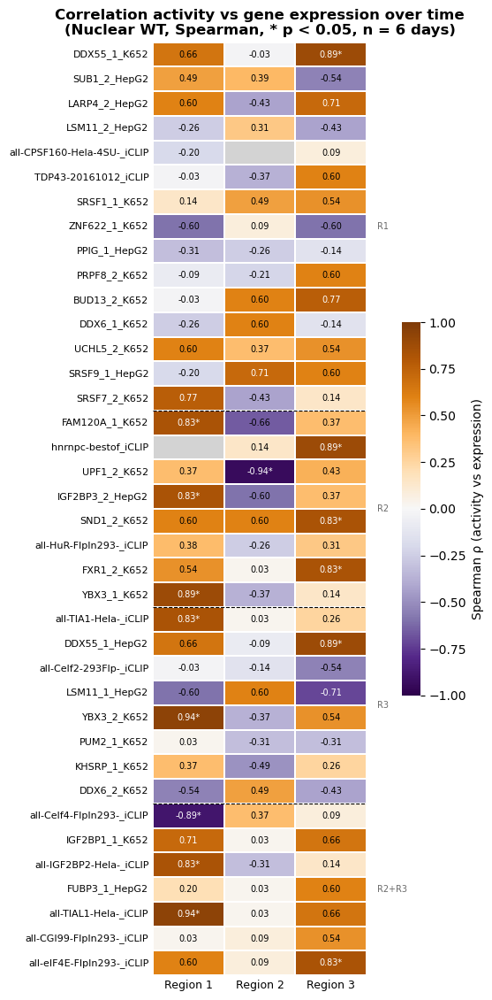

In [32]:
# ---- Correlation between regulator activity and its own gene expression over time ----
# Rows       = all top-15 regulators (R1 / R2 / R3 lists picked at Nuclear WT D35), in the same
#              order and groups as the Welch-over-time heatmaps (ordered_regs / reg_group_info).
# Columns    = the 3 regions: every regulator is correlated in every region.
# Activity   = Welch score of that CLIP in the region, Nuclear WT, per day, oriented so that
#              higher = stronger effect (R1: proximal enrichment, R2: proximal depletion,
#              R3: distal enrichment).
# Expression = the RBP's gene, log2(normalised counts + 1), Nuclear WT, mean of replicates.
# Spearman correlation across the 6 days (D0-D35): n = 6, so p-values are indicative only.
from scipy.stats import spearmanr, pearsonr

days = [f"D{d}" for d in DAY_ORDER]
region_ids = [1, 2, 3]
activity = pd.concat([matrix_region1, matrix_region2, matrix_region3], axis=1).replace([np.inf, -np.inf], np.nan)


def nuclear_wt_expression(rbp):
    """Mean Nuclear WT log2 expression per day of an RBP's gene (None if not in df_genes)."""
    symbol = RBP_TO_SYMBOL.get(rbp, rbp)
    if symbol not in df_genes.index:
        return None
    long = gene_expression_over_time(symbol, df_genes, meta_genes)
    long = long[(long["Compartment"] == "Nuclear") & (long["Genotype"] == "WT")]
    return long.groupby("Day")["log2_expression"].mean().reindex(DAY_ORDER).set_axis(days)


records, skipped = [], []
for reg in ordered_regs:
    rbp = get_RBP_name(reg)
    expr = nuclear_wt_expression(rbp)
    if expr is None:
        skipped.append(reg)
        continue
    for r in region_ids:
        act = activity.loc[reg, [f"Nuclear_WT_{d}_region{r}" for d in days]].set_axis(days)
        ok = act.notna() & expr.notna()
        rec = {"regulator": reg, "RBP": rbp, "group": group_of[reg], "region": f"Region {r}",
               "spearman_rho": np.nan, "spearman_p": np.nan, "pearson_r": np.nan, "pearson_p": np.nan,
               "n_days": int(ok.sum())}
        if ok.sum() >= 4 and act[ok].nunique() > 1:   # flat activity (e.g. all 0) -> undefined
            rec["spearman_rho"], rec["spearman_p"] = spearmanr(act[ok], expr[ok])
            rec["pearson_r"], rec["pearson_p"] = pearsonr(act[ok], expr[ok])
        records.append(rec)
if skipped:
    print(f"Skipped (modification / gene not in expression table): {skipped}")

corr_activity_expression = pd.DataFrame(records)
corr_dir = f"{figures_subfolder}/top_regulators_activity_vs_expression"
os.makedirs(corr_dir, exist_ok=True)
save_table(corr_activity_expression, f"{tables_subfolder}/correlation_Welch_activity_vs_own_gene_expression_D0_to_D35_NuclearCTRL_top15_global_regulators_per_region.csv", index=False,
           legend="Table behind heatmap_correlation_activity_vs_gene_expression_NuclearWT_top15_regulators.pdf: one "
                  "row per top-15 regulator (CLIP dataset; RNA modifications and RBPs missing from the expression "
                  "table left out) and region (R1, R2, R3): regulator, RBP, top-15 list(s) it belongs to (group), "
                  "Spearman rho / p and Pearson r / p between its Welch score in the region (nuclear CTRL, oriented "
                  "so that higher = stronger effect) and the nuclear CTRL expression of its own gene (log2(normalised "
                  "counts + 1), mean of replicates) across the 6 days D0-D35, and n_days = days with both values "
                  "(NaN = fewer than 4 days or flat activity).")

rows = [reg for reg in ordered_regs if reg not in skipped]
rho_mat = corr_activity_expression.pivot(index="regulator", columns="region", values="spearman_rho").loc[rows]
p_mat_corr = corr_activity_expression.pivot(index="regulator", columns="region", values="spearman_p").loc[rows]

# ── Heatmap: regulators x regions ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, max(4, len(rows) * 0.3)))
sns.heatmap(rho_mat, cmap=cm.PuOr_r, center=0, vmin=-1, vmax=1,
            yticklabels=rows, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Spearman ρ (activity vs expression)", "shrink": 0.4, "pad": 0.12}, ax=ax)
ax.set_facecolor("lightgrey")   # NaN: activity flat over time in that region

# rho values (drawn by hand: seaborn's annot only fills the first rows on this matplotlib)
for i, reg in enumerate(rows):
    for j, region in enumerate(rho_mat.columns):
        rho, pval = rho_mat.loc[reg, region], p_mat_corr.loc[reg, region]
        if np.isnan(rho):
            continue
        ax.text(j + 0.5, i + 0.5, f"{rho:.2f}" + ("*" if pval < 0.05 else ""), ha="center", va="center",
                fontsize=7, color="white" if abs(rho) > 0.7 else "black")

# Regulator-group separators (horizontal) and labels on the right, as in the Welch heatmaps
row_pos = {reg: i for i, reg in enumerate(rows)}
for idx, (start, end, glabel) in enumerate(reg_group_info):
    members = [row_pos[reg] for reg in ordered_regs[start:end + 1] if reg in row_pos]
    if not members:
        continue
    if idx > 0:
        ax.axhline(min(members), color="black", linewidth=0.8, linestyle="--")
    ax.text(len(region_ids) + 0.15, (min(members) + max(members) + 1) / 2, glabel,
            fontsize=7, va="center", color="dimgrey")

ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8, length=0)
ax.tick_params(axis="x", labelsize=9, rotation=0, length=0)
ax.set_title("Correlation activity vs gene expression over time\n(Nuclear WT, Spearman, * p < 0.05, n = 6 days)",
             weight="bold")
plt.tight_layout()
save_figure(f"{corr_dir}/heatmap_correlation_activity_vs_gene_expression_NuclearWT_top15_regulators.pdf",
            legend="Spearman correlation, across the 6 days of MN differentiation (n = 6, p-values indicative only), "
                   "between the activity of each top-15 regulator (Welch score in the region, nuclear CTRL; higher = "
                   "stronger effect in every region) and the nuclear CTRL expression of its own gene (log2(normalised "
                   "counts + 1), mean of replicates). Rows grouped by top-15 list(s); * = p < 0.05; grey = activity flat "
                   "over time. RNA modifications and RBPs missing from the expression table are left out.")
plt.show()


<a id="apa-vs-nr"></a>
## APA vs nuclear retention: nuclear vs cytoplasmic activity of the top regulators

For the top-15 CLIPs of each region, plus the 7 RNA modifications, the next three cells take the maximum region score at D35 in WT, separately in the nuclear and cytoplasmic fractions (sign-flipped for R2 and R3, so that higher = stronger effect). Each regulator is then classified, with a threshold of −log10(0.05):
- **APA**: significant in both fractions. The isoform change is seen in the whole cell, consistent with a change in poly(A) site choice.
- **Nuclear retention**: significant in the nucleus only. Consistent with the isoform being retained in the nucleus.
- **Ambiguous**: anything else. Ambiguous modifications are dropped.

This gives `class_df_R{1,2,3}` (RBPs) and `df_cat_modif_R{1,2,3}` (modifications).

The scatter plots then show the nuclear vs cytoplasmic maximum for each region: RBPs in black, modifications in dark blue, the APA quadrant shaded pink and the nuclear-retention quadrant green. They also report the Pearson r within the APA and nuclear-retention groups. Saved as `top_regulators_APA_vs_nuclear_retention/scatter_nuclear_vs_cytoplasmic_welch_D35_CTRL_top15_R{1,2,3}_regulators.pdf`. The classification of the RBPs is written to `top_regulators_in_CTRL_region{1,2,3}.csv`. `pick_best` is defined but not used.

In [33]:

proximal_filtered = proximal[(proximal["Day"] == "D35") & (proximal["VCP"] == "Wildtype")]
records = []
for CLIP in R1_top15_long_names+modifs:
    clip = proximal_filtered[proximal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R1 = pd.DataFrame(records)

df_cat_modif_R1 = class_df_R1[class_df_R1['regulator'].isin(modifs)]
df_cat_modif_R1 = df_cat_modif_R1[~(df_cat_modif_R1['category'] == 'Ambiguous')]

class_df_R1 = class_df_R1[~class_df_R1['regulator'].isin(modifs)]

In [34]:

proximal_filtered = proximal[(proximal["Day"] == "D35") & (proximal["VCP"] == "Wildtype")]
records = []
for CLIP in R2_top15_long_names+modifs:
    clip = proximal_filtered[proximal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= negative_proximal_region[0]) & (clip['dist'] <= negative_proximal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= negative_proximal_region[0]) & (clip['dist'] <= negative_proximal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R2 = pd.DataFrame(records)


df_cat_modif_R2 = class_df_R2[class_df_R2['regulator'].isin(modifs)]
df_cat_modif_R2 = df_cat_modif_R2[~(df_cat_modif_R2['category'] == 'Ambiguous')]

class_df_R2 = class_df_R2[~class_df_R2['regulator'].isin(modifs)]

In [35]:

distal_filtered = distal[(distal["Day"] == "D35") & (distal["VCP"] == "Wildtype")]
records = []
for CLIP in R3_top15_long_names+modifs:
    clip = distal_filtered[distal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R3 = pd.DataFrame(records)

df_cat_modif_R3 = class_df_R3[class_df_R3['regulator'].isin(modifs)]
df_cat_modif_R3 = df_cat_modif_R3[~(df_cat_modif_R3['category'] == 'Ambiguous')]
class_df_R3 = class_df_R3[~class_df_R3['regulator'].isin(modifs)]

In [36]:
# Deduplicate: per RBP, prefer APA over others; break ties by largest |nuc - cyto| difference
def pick_best(group):
    apa = group[group['category'] == 'APA']
    pool = apa if not apa.empty else group
    return pool.loc[pool['nuc_cyto_diff'].idxmin()]  # most negative diff = biggest nuc vs cyto gap


In [37]:
palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b', 'Ambiguous': '#aaaaaa'}
thr = -np.log10(0.05)

from scipy.stats import pearsonr
from matplotlib.lines import Line2D


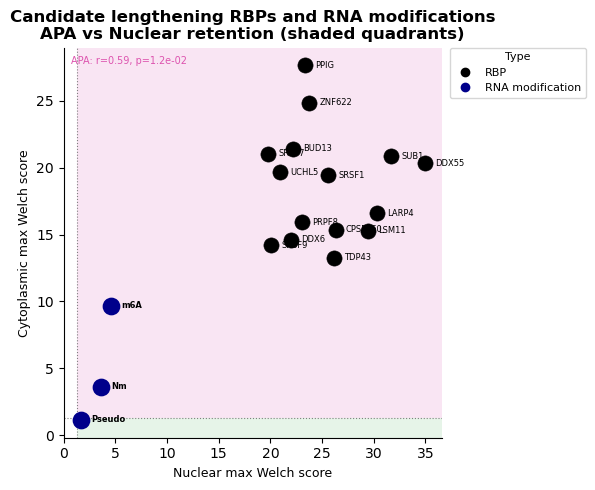

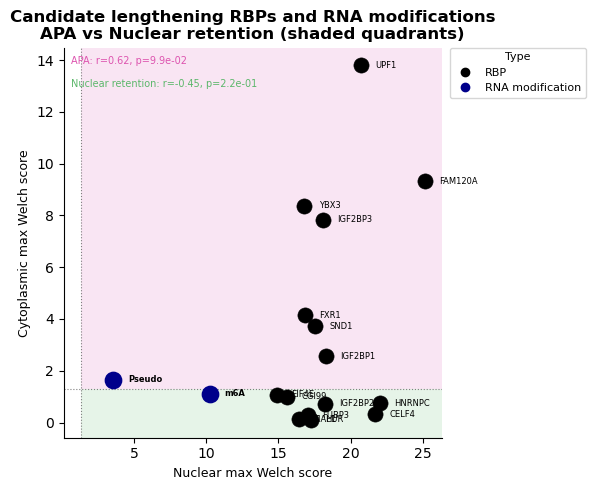

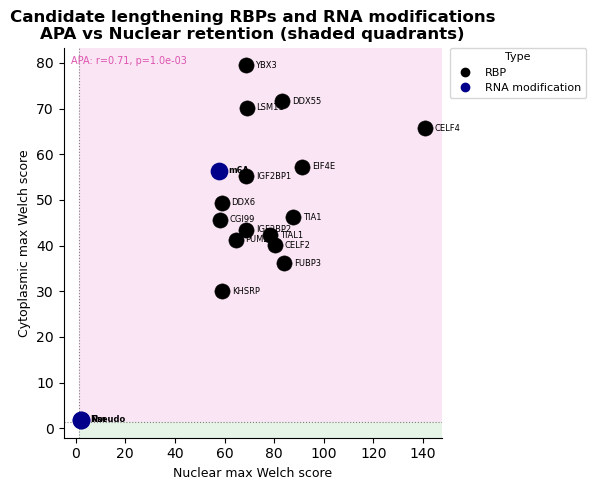

In [38]:
# Black-and-white markers, quadrants shaded by category instead

for region, class_df, modif_df, x_delay in zip(["R1", "R2", "R3"],
                                      [class_df_R1, class_df_R2, class_df_R3],
                                      [df_cat_modif_R1, df_cat_modif_R2, df_cat_modif_R3],
                                      [1, 1, 4]):
        
        
        corrs = {}
        for cat in ['APA', 'Nuclear retention']:
                sub = pd.concat([
                        class_df[class_df['category'] == cat][['nuclear_max', 'cyto_max']],
                        modif_df[modif_df['category'] == cat][['nuclear_max', 'cyto_max']],
                ])
                if len(sub) > 1:
                        r, p = pearsonr(sub['nuclear_max'], sub['cyto_max'])
                        corrs[cat] = (r, p)
        
        fig, ax = plt.subplots(figsize=(6, 5))

        for _, row in class_df.iterrows():
                ax.scatter(row['nuclear_max'], row['cyto_max'], color='black', s=120, zorder=3,
                        edgecolors='black', linewidths=0.4, marker='o')
                ax.text(row['nuclear_max'] + x_delay, row['cyto_max'], row['RBP'],
                        fontsize=6, va='center', color='black')

        for _, row in modif_df.iterrows():
                ax.scatter(row['nuclear_max'], row['cyto_max'], color='darkblue', s=120, zorder=4,
                        marker='o', linewidths=1.8)
                ax.text(row['nuclear_max'] + x_delay, row['cyto_max'], row['regulator'],
                        fontsize=6, va='center', color='black', fontweight='bold')

        # Quadrant threshold lines
        ax.axvline(thr, color='grey', linestyle=':', linewidth=0.8)
        ax.axhline(thr, color='grey', linestyle=':', linewidth=0.8)

        xlim = ax.get_xlim()
        ylim = ax.get_ylim()

        # Shade APA (top-right) in pink and Nuclear retention (bottom-right) in green
        ax.add_patch(mpatches.Rectangle((thr, thr), xlim[1] - thr, ylim[1] - thr,
                                        facecolor='#dd54af', alpha=0.15, zorder=0, linewidth=0))
        ax.add_patch(mpatches.Rectangle((thr, ylim[0]), xlim[1] - thr, thr - ylim[0],
                                        facecolor='#5cb76b', alpha=0.15, zorder=0, linewidth=0))
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)

        marker_handles = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='black',
                markersize=6, label='RBP'),
        Line2D([0], [0], marker='o', color='darkblue', markersize=6, linewidth=0, label='RNA modification'),
        ]
        ax.legend(handles=marker_handles, title='Type', fontsize=8, title_fontsize=8,
                loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

        for i, (cat, (r, p)) in enumerate(corrs.items()):
                ax.text(0.02, 0.98 - i * 0.06, f'{cat}: r={r:.2f}, p={p:.1e}',
                        transform=ax.transAxes, fontsize=7, color=palette[cat],
                        va='top', ha='left')

        ax.set_xlabel('Nuclear max Welch score', fontsize=9)
        ax.set_ylabel('Cytoplasmic max Welch score', fontsize=9)
        ax.set_title('Candidate lengthening RBPs and RNA modifications\nAPA vs Nuclear retention (shaded quadrants)', weight='bold')
        sns.despine(ax=ax)
        plt.tight_layout()

        region_window = {"R1": "max Welch score in [-350, -50] nt upstream of the pPAS",
                         "R2": "max of the sign-flipped Welch score in [0, +150] nt downstream of the pPAS (depletion)",
                         "R3": "max of the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS"}[region]
        save_figure(f"{figures_subfolder}/top_regulators_APA_vs_nuclear_retention/scatter_nuclear_vs_cytoplasmic_welch_D35_CTRL_top15_{region}_regulators.pdf",
                    legend=f"Top 15 {region} regulators (black, RBP name) and RNA modifications (dark blue): {region_window}, "
                           "in the nuclear (x) vs cytoplasmic (y) fraction of CTRL motor neurons at D35. Dotted lines = "
                           "-log10(0.05). Pink quadrant = APA (significant in both fractions), green = nuclear retention "
                           "(nucleus only); modifications in neither are not shown. Pearson r within the APA and "
                           "nuclear-retention groups at the top left.")
        plt.show()




In [39]:
for k, class_df in {1: class_df_R1, 2: class_df_R2, 3: class_df_R3}.items():
    save_table(class_df, f"{tables_subfolder}/top15_global_regulators_NuclearCTRL_D35_{figures.REGION_FILE_NAMES[k]}_APA_vs_nuclear_retention_class.csv",
               pattern="top15_global_regulators_NuclearCTRL_D35_<region>_APA_vs_nuclear_retention_class.csv",
               legend="Top 15 global regulators (CLIP datasets; RNA modifications excluded) of one region (file name: "
                      "region1_upstream_pPAS = R1, region2_downstream_pPAS = R2, region3_upstream_dPAS = R3), selected "
                      "in the nuclear fraction of CTRL motor neurons at D35, with their APA / nuclear-retention class: "
                      "regulator (CLIP dataset), RBP, nuclear_max and cyto_max = maximum Welch score in the region at "
                      "D35 in CTRL in the nuclear and cytoplasmic fractions (sign-flipped for R2 and R3, so that "
                      "higher = stronger effect), category (APA = both > -log10(0.05), Nuclear retention = nucleus "
                      "only, Ambiguous = otherwise) and nuc_cyto_diff = nuclear_max - cyto_max.")

<a id="apa-vs-nr-all"></a>
### Classification of all regulators

Same classification for **every** regulator, in all three regions. A regulator with no data in any one of the regions is skipped entirely. Saved as `../Tables/Figure_global_regulators_NuclearWT_D35/APA_vs_nuclear_retention_class_max_Welch_score_nuclear_vs_cytoplasmic_all_regulators_CTRL_D35_regions_R1_R2_R3.csv`. The next cell is a quick scatter plot of the Region 2 classification.

In [40]:
# Look at all RBPs 

# R1
proximal_filtered = proximal[(proximal["Day"] == "D35") & (proximal["VCP"] == "Wildtype")]
distal_filtered = distal[(distal["Day"] == "D35") & (distal["VCP"] == "Wildtype")]

records = []
for reg in matrix_merged_grouped.index:
    clip = proximal_filtered[proximal_filtered['regulator'] == reg]
    
    # R1
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = cyto['mean_score_lg10']
    
    
    nuclear_max_R1 = nuc['mean_score_lg10'].max()
    cyto_max_R1    = cyto['mean_score_lg10'].max()
    
    
    if nuclear_max_R1 > -np.log10(0.05) and cyto_max_R1 > -np.log10(0.05):
        category_R1 = 'APA'
    elif nuclear_max_R1 > -np.log10(0.05) and cyto_max_R1 < -np.log10(0.05):
        category_R1 = 'Nuclear retention'
    else:
        category_R1 = 'Ambiguous'

    
    # R2
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= negative_proximal_region[0]) & (clip['dist'] <= negative_proximal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= negative_proximal_region[0]) & (clip['dist'] <= negative_proximal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max_R2 = nuc['mean_score_lg10'].max()
    cyto_max_R2   = cyto['mean_score_lg10'].max()
    
    if nuclear_max_R2 > -np.log10(0.05) and cyto_max_R2 > -np.log10(0.05):
        category_R2 = 'APA'
    elif nuclear_max_R2 > -np.log10(0.05) and cyto_max_R2 < -np.log10(0.05):
        category_R2 = 'Nuclear retention'
    else:
        category_R2 = 'Ambiguous'



    clip = distal_filtered[distal_filtered['regulator'] == reg]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max_R3 = nuc['mean_score_lg10'].max()
    cyto_max_R3    = cyto['mean_score_lg10'].max()
    
    
    
    if nuclear_max_R3 > -np.log10(0.05) and cyto_max_R3 > -np.log10(0.05):
        category_R3 = 'APA'
    elif nuclear_max_R3 > -np.log10(0.05) and cyto_max_R3 < -np.log10(0.05):
        category_R3 = 'Nuclear retention'
    else:
        category_R3 = 'Ambiguous'

    records.append({
        'regulator': reg,
        'RBP': get_RBP_name(reg),
        'nuclear_max_R1': nuclear_max_R1,
        'cyto_max_R1': cyto_max_R1,
        'category_R1': category_R1,
        'nuc_cyto_diff_R1': nuclear_max_R1 - cyto_max_R1,  # more negative = larger nuc-specific effect
        'nuclear_max_R2': nuclear_max_R2,
        'cyto_max_R2': cyto_max_R2,
        'category_R2': category_R2,
        'nuc_cyto_diff_R2': nuclear_max_R2 - cyto_max_R2,  # more negative = larger nuc-specific effect
        'nuclear_max_R3': nuclear_max_R3,
        'cyto_max_R3': cyto_max_R3,
        'category_R3': category_R3,
        'nuc_cyto_diff_R3': nuclear_max_R3 - cyto_max_R3,  # more negative = larger nuc-specific effect
    })
    
all_class = pd.DataFrame(records).sort_values(by='nuclear_max_R2')
save_table(all_class, f"{tables_subfolder}/APA_vs_nuclear_retention_class_max_Welch_score_nuclear_vs_cytoplasmic_all_regulators_CTRL_D35_regions_R1_R2_R3.csv",
           legend="Every regulator (CLIP datasets and RNA modifications) at D35 in CTRL, sorted by nuclear_max_R2: for "
                  "each region (R1, R2, R3), the max Welch score in the nuclear and cytoplasmic fractions (same windows "
                  "and signs as the scatter plots: sign-flipped for R2 and R3), their difference (nuc_cyto_diff), and "
                  "the category (APA = > -log10(0.05) in both fractions, Nuclear retention = nucleus only, Ambiguous = "
                  "otherwise). Regulators missing a region are left out.")

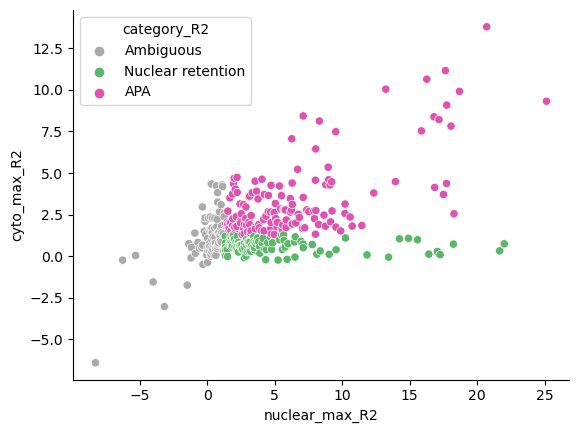

In [41]:
sns.scatterplot(data=all_class, 
                x='nuclear_max_R2',
                y='cyto_max_R2',
                hue='category_R2',
                palette=palette)
sns.despine()

<a id="condensates"></a>
## Condensate propensity of APA vs nuclear-retention regulators (Region 2)

Loads the condensate propensity z-score (`Condensate_Zscore`) of each CLIP from the 6th sheet of the AxonLoc supplementary tables. Excel turned some values into dates: `normalize_condensate_zscore` converts them back (day.month → number), and a few remaining entries are set by hand. The table is then reduced to one row per RBP.

The top Region 2 regulators are split into **APA** and **Nuclear retention** (from `class_df_R2`). **All** holds every other RBP in the table. Pairwise tests: a Shapiro test on every group selects Welch's t-test if all are normal, Mann–Whitney U otherwise. P-values are not corrected. Saved as `top_regulators_condensate_propensity/boxplot_condensate_zscore_top15_R2_regulators_APA_vs_NR.pdf`. The last two cells list the RBPs in each group.

In [42]:
from pathlib import Path


workbook_path = Path(f'{AXONLOC_CSV}')
xl = pd.ExcelFile(workbook_path)

from datetime import date, datetime
import numpy as np


def normalize_condensate_zscore(value):
    if pd.isna(value):
        return value

    if isinstance(value, (pd.Timestamp, datetime, date, np.datetime64)):
        timestamp = pd.Timestamp(value)
        return float(f'{timestamp.day}.{timestamp.month}')

    if isinstance(value, str):
        stripped = value.strip()
        parsed = pd.to_datetime(stripped, errors='coerce')
        if pd.notna(parsed):
            return float(f'{parsed.day}.{parsed.month}')

    return pd.to_numeric(value, errors='coerce')


# Load the first sheet as a starting point for exploration.
first_sheet = xl.sheet_names[5]
df = xl.parse(first_sheet)

if 'Condensate_Zscore' in df.columns:
    df['Condensate_Zscore'] = df['Condensate_Zscore'].map(normalize_condensate_zscore)
    df = df.dropna(subset=['Condensate_Zscore']).copy()
    
    
df.set_index('Clips', inplace=True)

df.loc['AARS1_1_K652', 'Condensate_Zscore'] = 2.08
df.loc['AARS1_2_K652', 'Condensate_Zscore'] = 2.08
df.loc['DGCR8_1_K652', 'Condensate_Zscore'] = 2.05
df.loc['DGCR8_2_K652', 'Condensate_Zscore'] = 2.05
df.loc['EFTUD2_1_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_2_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_1_K652', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_2_K652', 'Condensate_Zscore'] = 2.09
df.loc['GEMIN5_1_K652', 'Condensate_Zscore'] = 2.02
df.loc['GEMIN5_2_K652', 'Condensate_Zscore'] = 2.02
df.loc['LARP7_1_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_2_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_1_K652', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_2_K652', 'Condensate_Zscore'] = 2.09
df.loc['PPIL4_1_K652', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_2_K652', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_1_HepG2', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_2_HepG2', 'Condensate_Zscore'] = 2.08
df.loc['PUS1_1_K652', 'Condensate_Zscore'] = 2.01
df.loc['PUS1_2_K652', 'Condensate_Zscore'] = 2.01
df.loc['SERBP1_1_K652', 'Condensate_Zscore'] = 3.03
df.loc['SERBP1_2_K652', 'Condensate_Zscore'] = 3.03
df.loc['SFPQ_1_HepG2', 'Condensate_Zscore'] = 3.06
df.loc['SFPQ_2_HepG2', 'Condensate_Zscore'] = 3.06
df.loc['TRA2A_1_HepG2', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_2_HepG2', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_1_K652', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_2_K652', 'Condensate_Zscore'] = 3.05

# Keep only the first row for each RBP.
df['RBPs'] = df["RBPs"].str.upper()
df.set_index('RBPs', inplace=True)
df = df[~df.index.duplicated(keep='first')].copy()

In [43]:
candidates_nuc_ret = class_df_R2[class_df_R2['category'] == 'Nuclear retention']['RBP'].tolist()
candidates_apa = class_df_R2[class_df_R2['category'] == 'APA']['RBP'].tolist()

candidates_apa = [candidate for candidate in candidates_apa if candidate in df.index]
candidates_nuc_ret = [candidate for candidate in candidates_nuc_ret if candidate in df.index]

df["Category"] = "All"

df.loc[candidates_nuc_ret, "Category"] = "Nuclear retention"

df.loc[candidates_apa, "Category"] = "APA"


All is not normal (p=1.48e-06)


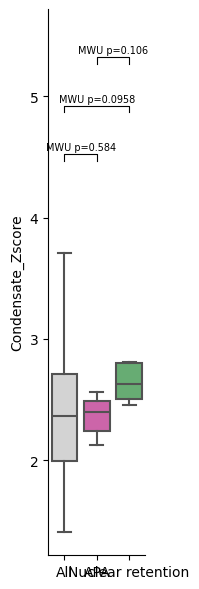

In [44]:

import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

category_order = ['All', 'APA', 'Nuclear retention']

# Decide test once based on normality of all groups
all_normal = True
for group in category_order:
    g = df.loc[df['Category'] == group, 'Condensate_Zscore'].dropna()
    if len(g) >= 3:
        if stats.shapiro(g).pvalue <= 0.05:
            print(f"{group} is not normal (p={stats.shapiro(g).pvalue:.3g})")
            all_normal = False
            break
    else:
        all_normal = False
        break

test_name = 'Welch' if all_normal else 'MWU'

pairwise = {}
for g1, g2 in combinations(category_order, 2):
    a = df.loc[df['Category'] == g1, 'Condensate_Zscore'].dropna()
    b = df.loc[df['Category'] == g2, 'Condensate_Zscore'].dropna()
    if all_normal:
        _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
    else:
        _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        # _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
    pairwise[(g1, g2)] = p


fig, ax = plt.subplots(figsize=(2, 6))
sns.boxplot(data=df[df['Category'].isin(category_order)],
            y='Condensate_Zscore', x='Category', order=category_order,
            palette={'All': 'lightgray', 'APA': '#dd54af', 'Nuclear retention': '#5cb76b'},
            showfliers=False, ax=ax)
sns.despine(ax=ax)

# Draw significance brackets
y_top = df['Condensate_Zscore'].max()
bracket_levels = [y_top + 0.3, y_top + 0.7, y_top + 1.1]
x_positions = {cat: i for i, cat in enumerate(category_order)}

for level, (g1, g2) in zip(bracket_levels, combinations(category_order, 2)):
    x1, x2 = x_positions[g1], x_positions[g2]
    p = pairwise[(g1, g2)]
    ax.plot([x1, x1, x2, x2], [level - 0.05, level, level, level - 0.05],
            color='black', linewidth=0.8)
    ax.text((x1 + x2) / 2, level + 0.02,
            f'{test_name} p={p:.3g}', ha='center', va='bottom', fontsize=7)

ax.set_ylim(bottom=None, top=bracket_levels[-1] + 0.4)
ax.set_xlabel('')
plt.tight_layout()
save_figure(f"{figures_subfolder}/top_regulators_condensate_propensity/boxplot_condensate_zscore_top15_R2_regulators_APA_vs_NR.pdf",
            legend="Condensate propensity z-score (AxonLoc supplementary tables, one value per RBP) of the top 15 R2 "
                   "regulators classified as APA (pink) or nuclear retention (green) at D35 in CTRL, vs all other RBPs "
                   "of the table (grey). Pairwise two-sided tests: Welch's t-test if every group passes a Shapiro test, "
                   "Mann-Whitney U otherwise (test name on the brackets; p uncorrected). Outliers not drawn.")
plt.show()

In [45]:
candidates_nuc_ret

['HNRNPC', 'CELF4', 'HUR', 'FUBP3', 'TIAL1']

In [46]:
candidates_apa

['FAM120A', 'UPF1', 'IGF2BP1', 'IGF2BP3', 'SND1', 'FXR1', 'YBX3']

<a id="vcp-ki"></a>
## Top regulators in VCP knock-in cells ± ML240

Loads the Welch profiles (same score, 50-nt bins from −1000 to +200 nt) of the VCP knock-in experiment. Conditions are untreated / ML240-treated cells of each line (WT, VCP-KI, VCP, TDP43), in the nuclear and cytoplasmic fractions.

In [47]:
from cliptools.analysis import load_and_combine_integrated_CLIP


path_to_processed_RBPs = f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/CLIP"

nb_nucleotides_upstream = -1000
nb_nucleotides_downstream = 200
length_region = 50

treatments = [
    "Untreated_TDP43_Cyto",
    "Ml240_TDP43_Cyto",
    "Untreated_TDP43_Nuc",
    "Ml240_TDP43_Nuc",
    "Untreated_VCP_Cyto",
    "Ml240_VCP_Cyto",
    "Untreated_VCP_KI_Cyto",
    "Ml240_VCP_KI_Cyto",
    "Untreated_VCP_KI_Nuc",
    "Ml240_VCP_KI_Nuc",
    "Untreated_VCP_Nuc",
    "Ml240_VCP_Nuc",
    "Untreated_WT_Cyto",
    "Ml240_WT_Cyto",
    "Untreated_WT_Nuc",
    "Ml240_WT_Nuc",
]

df_results_proximals = load_and_combine_integrated_CLIP(path_to_processed_RBPs, prefix='proximal')
df_results_distals = load_and_combine_integrated_CLIP(path_to_processed_RBPs, prefix='distal')



In [48]:
def get_RBP_name(clip_name):
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name:
        return clip_name.split('_')[0]        
    else:
        return clip_name.split('-')[1].upper()

In [49]:
class_df_R2['regulator'].values

array(['FAM120A_1_K652', 'hnrnpc-bestof_iCLIP',
       'all-Celf4-FlpIn293-_iCLIP', 'UPF1_2_K652', 'IGF2BP1_1_K652',
       'all-IGF2BP2-Hela-_iCLIP', 'IGF2BP3_2_HepG2', 'SND1_2_K652',
       'all-HuR-FlpIn293-_iCLIP', 'FUBP3_1_HepG2', 'FXR1_2_K652',
       'YBX3_1_K652', 'all-TIAL1-Hela-_iCLIP',
       'all-CGI99-FlpIn293-_iCLIP', 'all-eIF4E-FlpIn293-_iCLIP'],
      dtype=object)

<a id="vcp-ki-r2-barplots"></a>
### Region 2 depletion of the top Region 2 regulators

For every top-15 Region 2 RBP (`class_df_R2`, all categories), the Region 2 depletion (−min Welch score in [0, 150] nt downstream of the pPAS) in the nuclear fraction of untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells. Saved as `top_regulators_VCP-KI_ML240/barplot_R2_depletion_nuclear_VCP-KI_ML240_top15_R2_regulators.pdf`. The `region_1` / `region_2` variables in this cell are not used.

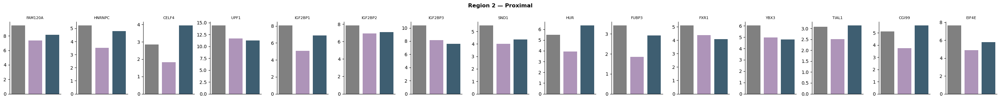

In [50]:

# Barplots for significant RBPs per region
# sig_region1 → region_1 of proximals (max enrichment near pPAS)
# sig_region2 → region_2 of proximals (-min, i.e. depletion downstream)
# sig_region3 → region_1 of distals (negated, so max = enrichment of proximal shift)

treatments_bar = ["Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc"]
palette_bar = ["gray", "#b18ebf", "#35607a"]
region_1 = (-350, 100)
region_2 = (-100, 200)

regions_config = [
    ("Region 2 — Proximal", class_df_R2['regulator'].values, df_results_proximals, negative_proximal_region, 'negmin'),
]

for region_title, rbp_list, df_res, region, mode in regions_config:
    n = len(rbp_list)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 3))
    if n == 1:
        axes = [axes]
    for i, rbp in enumerate(rbp_list):
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        y_vals = sub_r.max().values if mode == 'max' else -sub_r.min().values
        sns.barplot(ax=axes[i], x=treatments_bar, y=y_vals, palette=palette_bar)
        axes[i].set_title(get_RBP_name(rbp), fontsize=8)
        axes[i].set_xticks([])
        axes[i].axhline(0, color='gray', linewidth=0.5)
        sns.despine(ax=axes[i])
    # axes[0].set_ylabel("max -log10(p)·dPUD")
    fig.suptitle(region_title, weight='bold')
    plt.tight_layout()
save_figure(f"{figures_subfolder}/top_regulators_VCP-KI_ML240/barplot_R2_depletion_nuclear_VCP-KI_ML240_top15_R2_regulators.pdf",
            legend="VCP knock-in experiment: R2 depletion (-min Welch score in [0, +150] nt downstream of the pPAS) of "
                   "each top-15 R2 RBP (one panel each, CTRL D35 selection), in the nuclear fraction of untreated WT "
                   "(grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells.")
plt.show()

<a id="vcp-ki-profiles"></a>
### Welch profiles of every CLIP, per fraction

`welch_profiles_by_region_treatments` plots the Welch profile around the pPAS (proximal isoform) and the dPAS (distal isoform, sign-flipped so that positive = enrichment for a proximal shift), with one line per treatment. ±inf values are capped at the most extreme finite value.

The last cell draws one 2 × 2 figure per CLIP: nuclear (top) and cytoplasmic (bottom), proximal (left) and distal (right), for untreated WT, untreated VCP-KI and ML240-treated VCP-KI. Saved as `top_regulators_VCP-KI_ML240/welch_profiles_per_CLIP/<CLIP>.pdf`. This loops over every CLIP dataset, so it is slow and opens many figures. The commented cell above it is an older version with one figure per fraction.

In [51]:
def welch_profiles_by_region_treatments(df_results_proximals, df_results_distals, RBP, treatments, palette,
                                        proximal_region=(-1000, 200),
                                        distal_region=(-1000, 200),
                                        axes=None):
    """
    Welch profiles zoomed into the three regions (as in MN_diff welch_profiles_by_region),
    with one line per treatment instead of one line per day.
    Distal values are sign-flipped so that positive = enrichment for proximal shift.
    `axes`: optional pair of axes (proximal, distal) to draw into, e.g. one row of a larger
    figure; the caller is then responsible for the title / layout / saving.
    Returns (fig, axes).
    """
    cols = [f'-log10(pval)*dPUD_{t}' for t in treatments]

    def clip_and_distances(df_results):
        raw = df_results[RBP][cols].apply(pd.to_numeric, errors='coerce')
        finite = raw.replace([np.inf, -np.inf], np.nan)
        clipped = raw.replace([np.inf, -np.inf], [finite.max().max(), finite.min().min()])
        distances = np.array([nb_nucleotides_upstream + i * length_region for i in range(df_results[RBP].shape[0])])
        return clipped, distances

    clipped_prox, distances_prox = clip_and_distances(df_results_proximals)
    clipped_dist, distances_dist = clip_and_distances(df_results_distals)

    regions = [
        ('proximal_region', clipped_prox, distances_prox, proximal_region, 'Distance to pPAS (nt)', 1),
        ('distal_region',   clipped_dist, distances_dist, distal_region,   'Distance to dPAS (nt)', -1),
    ]

    standalone = axes is None
    if standalone:
        fig, axes = plt.subplots(1, len(regions), figsize=(10, 4))
    else:
        fig = axes[0].figure
    for ax, (name, clipped, distances, (xmin, xmax), xlabel, sign) in zip(axes, regions):
        mask = (distances >= xmin) & (distances <= xmax)
        sub_df = clipped.iloc[mask.tolist()] * sign
        for t, color in zip(treatments, palette):
            ax.plot(distances[mask], sub_df[f'-log10(pval)*dPUD_{t}'], label=t, color=color, marker='o', markersize=3)
        values = sub_df.values[np.isfinite(sub_df.values)]
        ax.set_ylim(values.min() - 2, values.max() + 2)
        ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
        ax.axvline(0, color='grey', linestyle='--', linewidth=0.8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('-log10(pval)*dPUD')
        ax.set_title(name)
        sns.despine(ax=ax)
    axes[-1].legend(title='Treatment', bbox_to_anchor=(1.05, 1), loc='upper left')

    if standalone:
        plt.suptitle(f"{RBP}", weight='bold')
        plt.tight_layout()
    return fig, axes



In [52]:
clip_names = matrix_merged_grouped.index
clip_names = [clip for clip in clip_names if clip not in modifs]

In [53]:


# for clip in clip_names:
#     treatments_bar = ["Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc"]
#     welch_profiles_by_region_treatments(df_results_proximals, 
#                                         df_results_distals,
#                                         clip, 
#                                         treatments_bar, 
#                                         palette_bar)
    
    
#     treatments_bar = ["Untreated_WT_Cyto", "Untreated_VCP_KI_Cyto", "Ml240_VCP_KI_Cyto"]
#     welch_profiles_by_region_treatments(df_results_proximals, 
#                                         df_results_distals,
#                                         clip, 
#                                         treatments_bar, 
#                                         palette_bar)

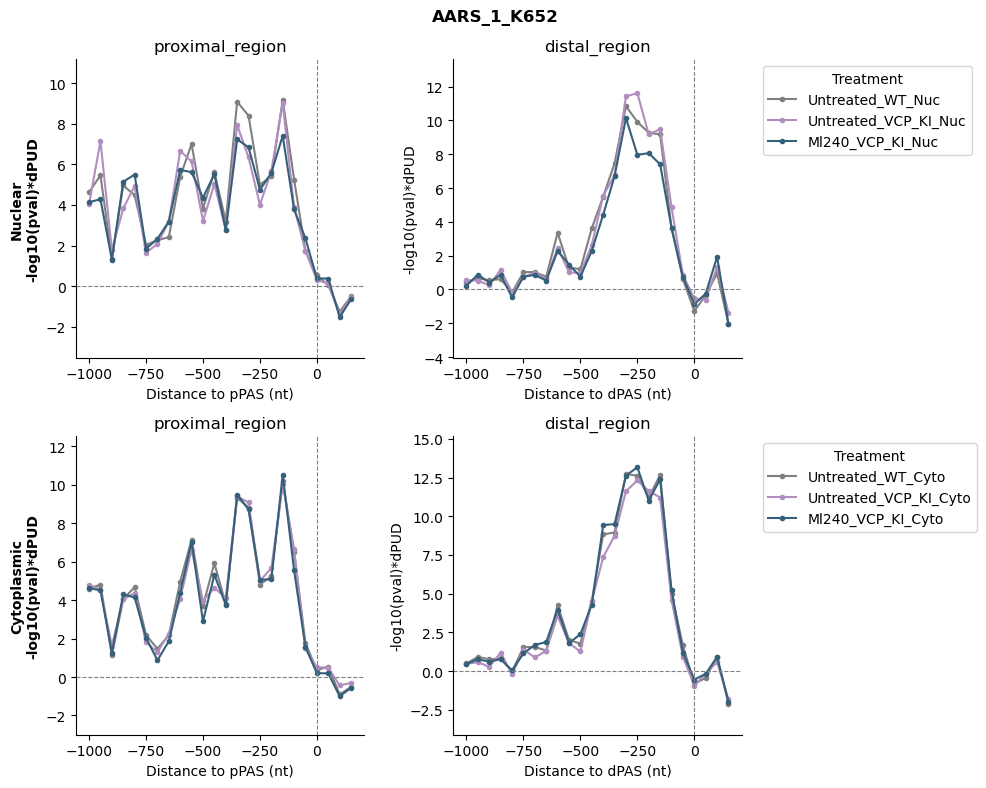

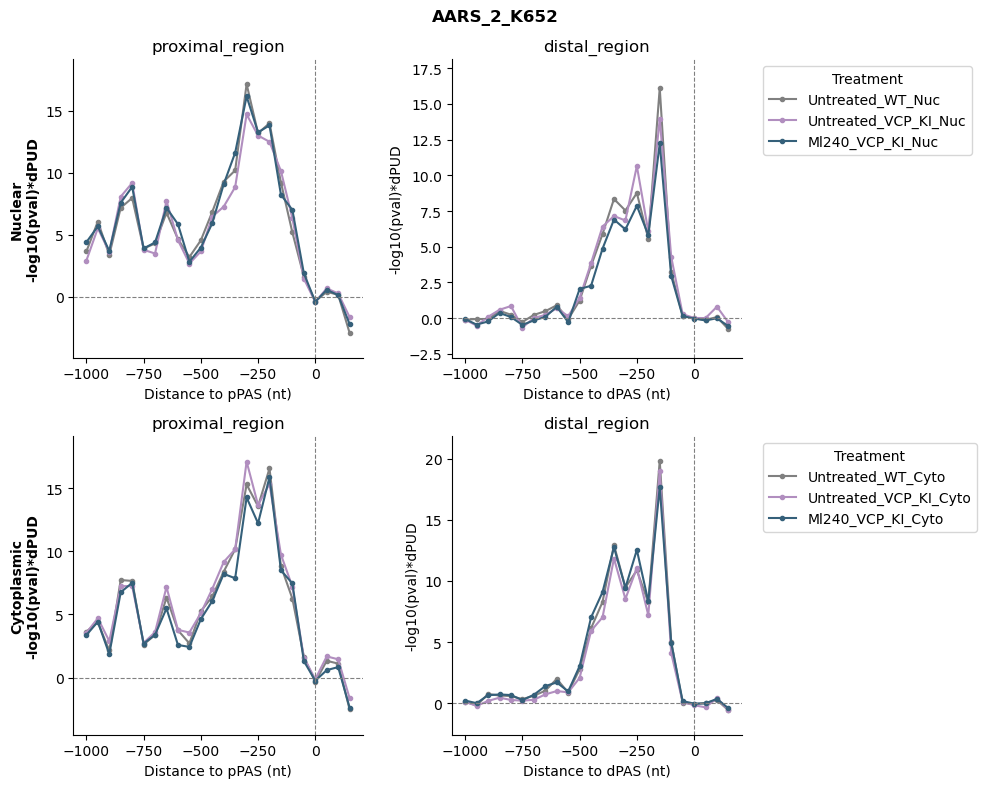

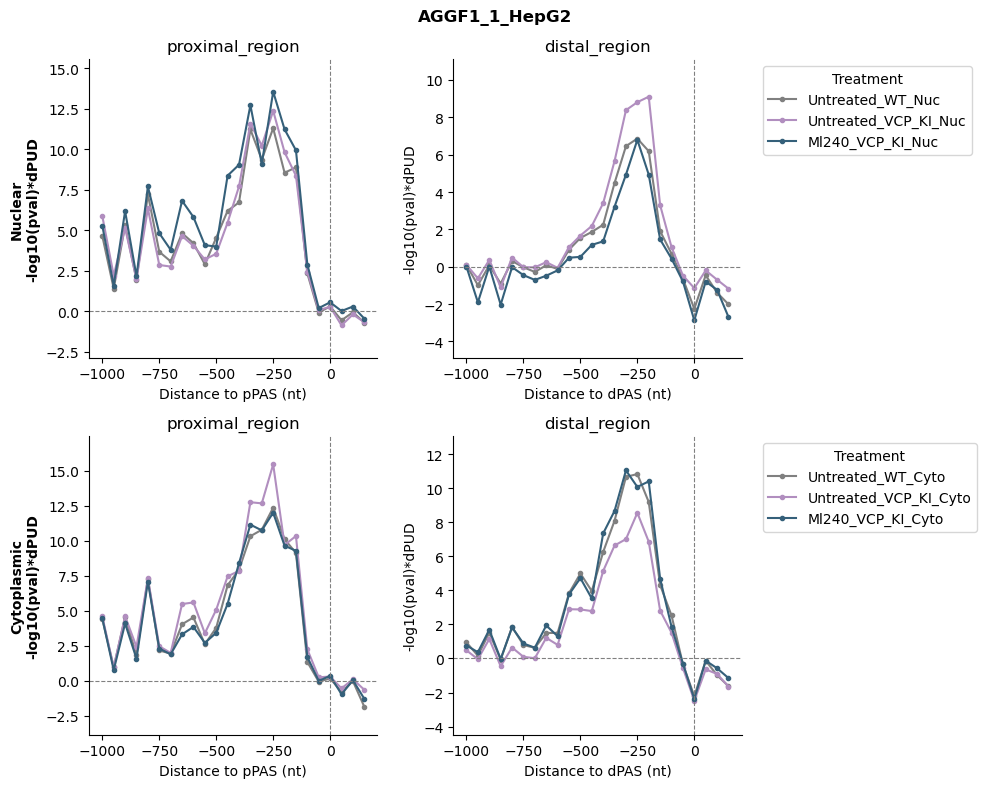

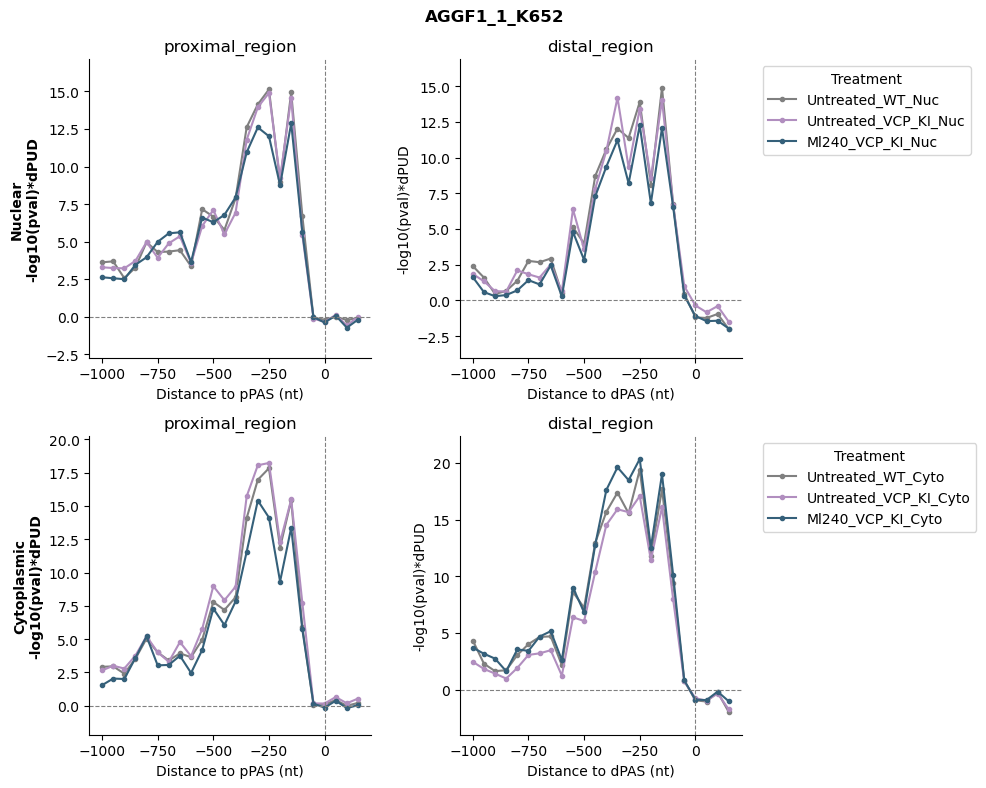

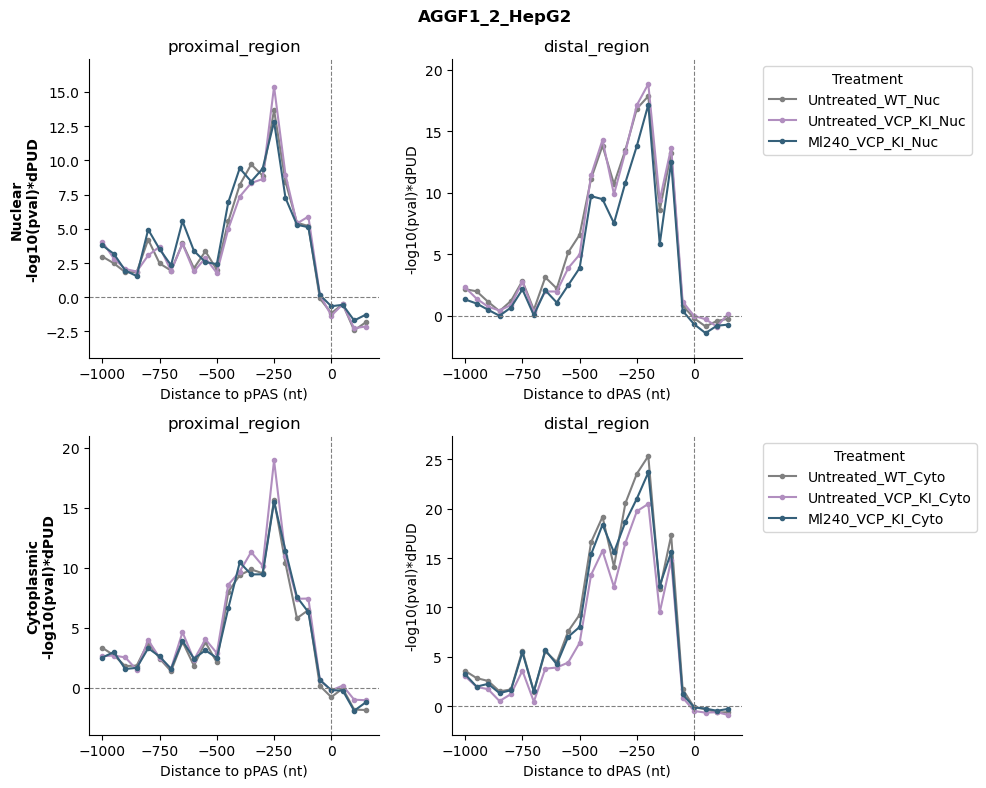

...

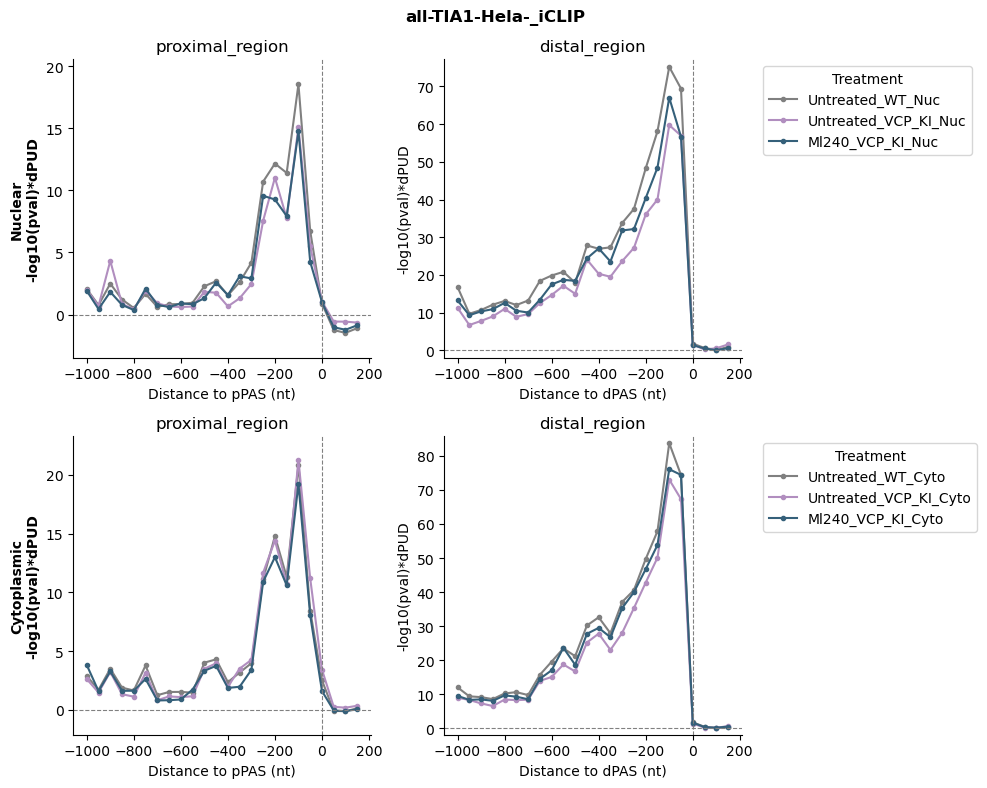

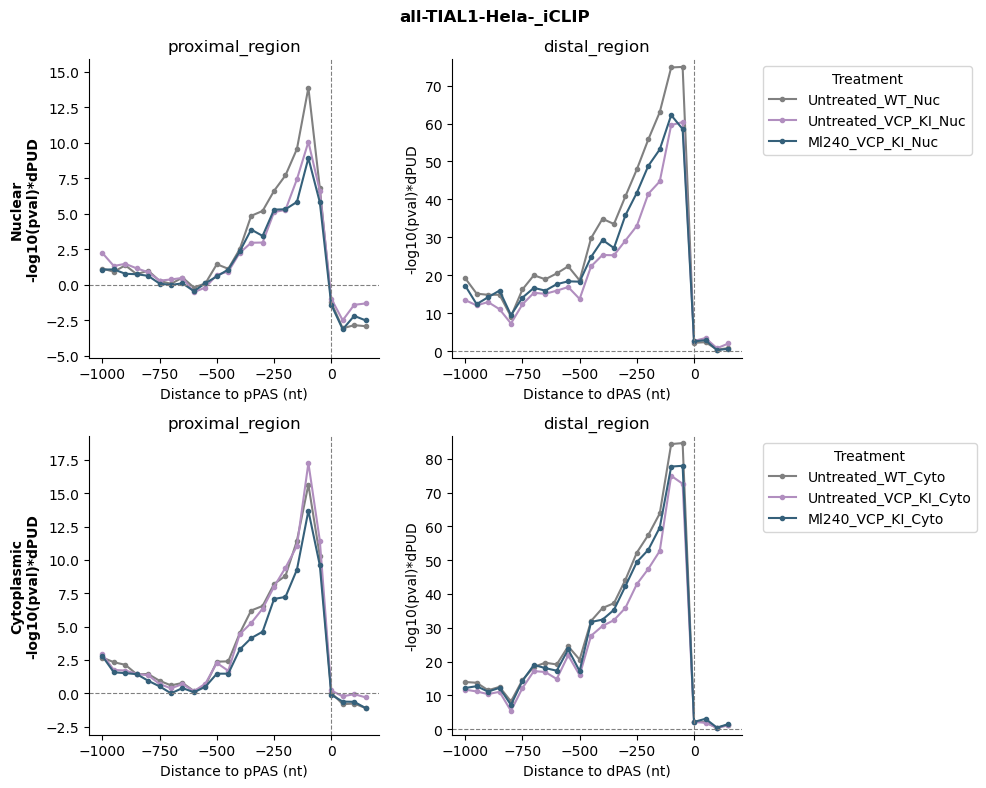

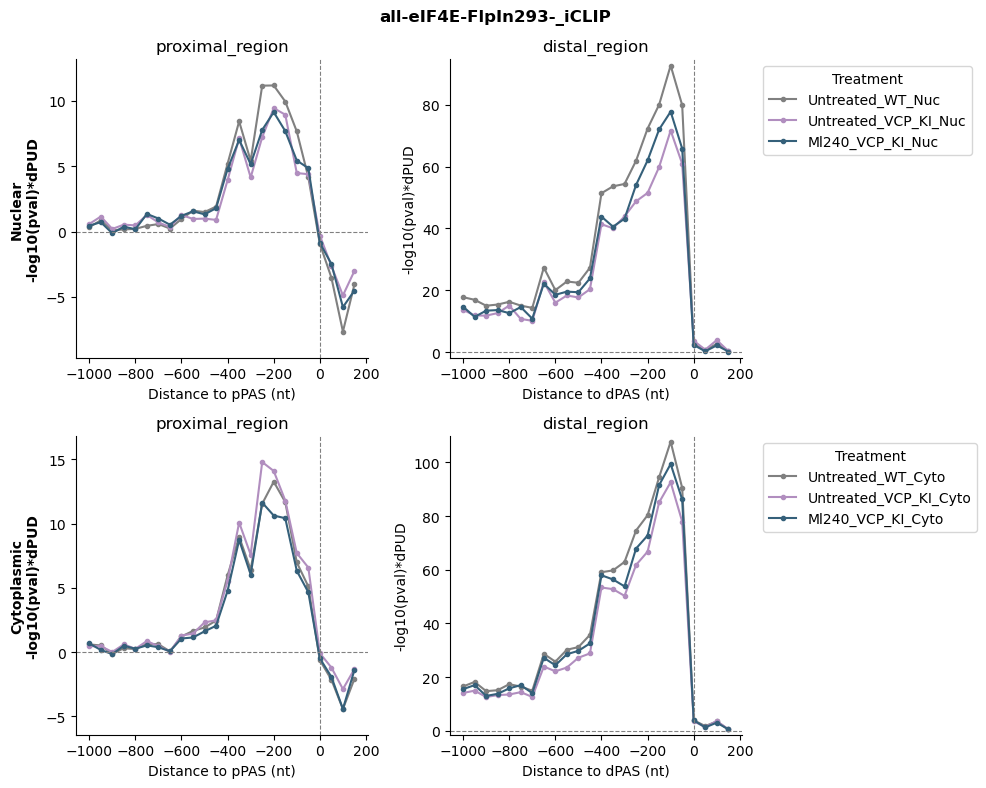

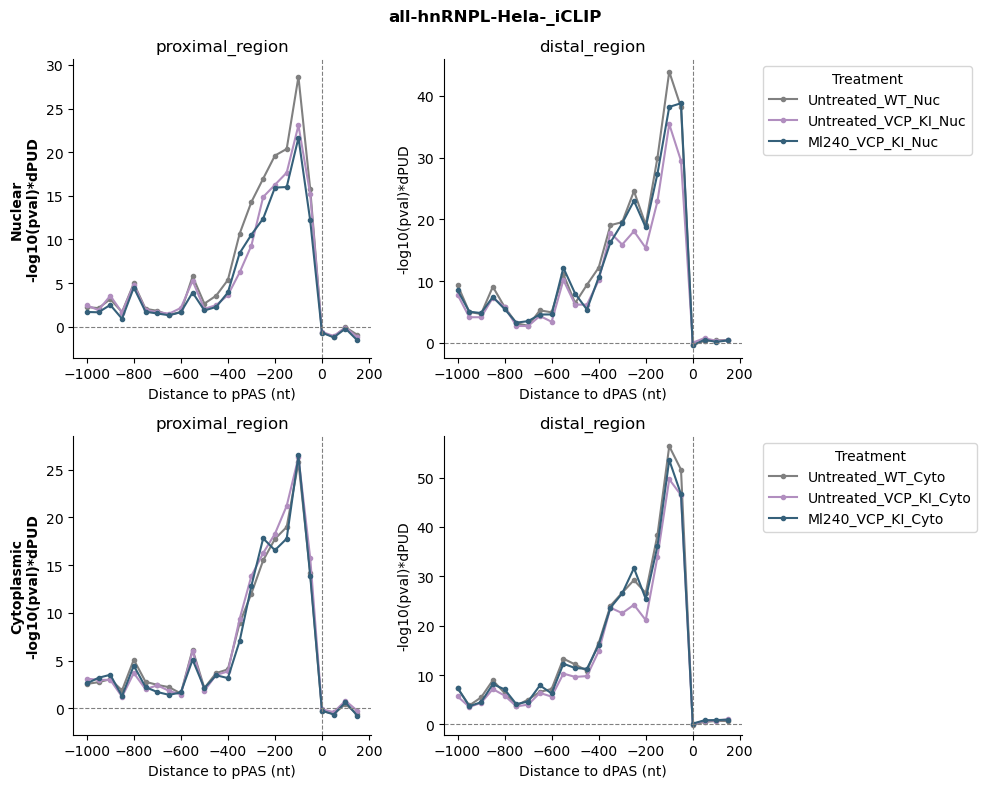

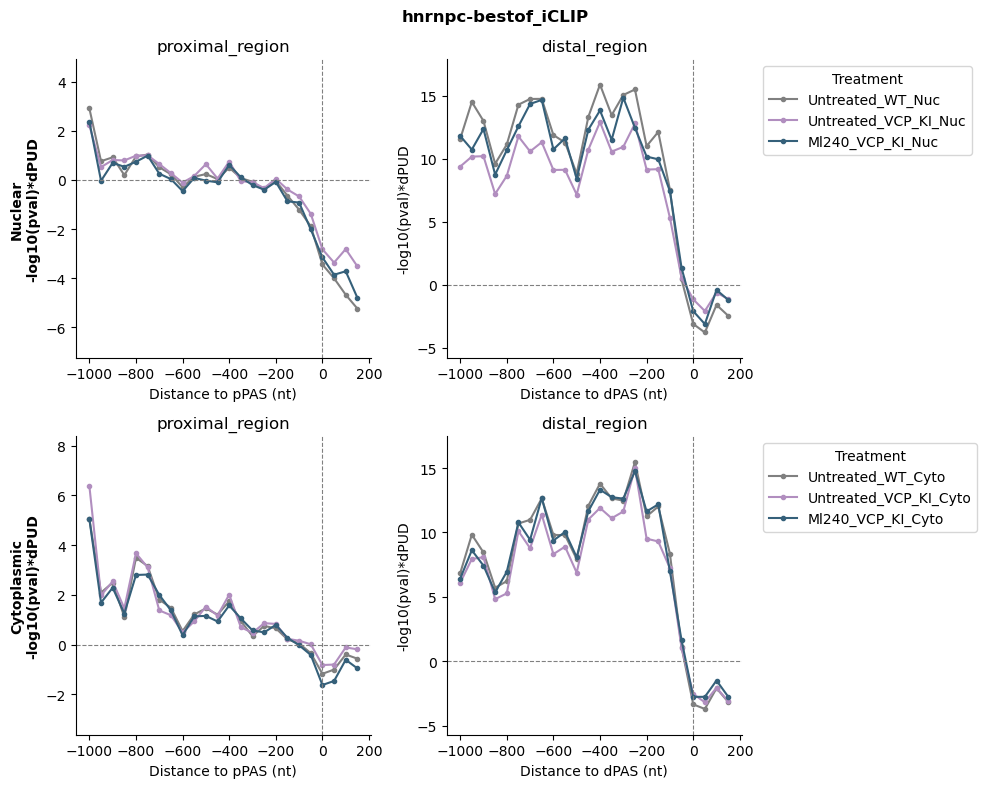

In [54]:
# rbp = 'all-Celf4-FlpIn293-_iCLIP'
compartment_treatments = {
    "Nuclear":     ["Untreated_WT_Nuc",  "Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"],
    "Cytoplasmic": ["Untreated_WT_Cyto", "Untreated_VCP_KI_Cyto", "Ml240_VCP_KI_Cyto"],
}
for rbp in clip_names:
    # One figure: top row = Nuclear, bottom row = Cytoplasmic (columns: proximal | distal)
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for row_axes, (compartment, treatments_bar) in zip(axes, compartment_treatments.items()):
        welch_profiles_by_region_treatments(df_results_proximals,
                                            df_results_distals,
                                            rbp,
                                            treatments_bar,
                                            palette_bar,
                                            axes=row_axes)
        row_axes[0].set_ylabel(f"{compartment}\n-log10(pval)*dPUD", weight='bold')
        
    fig.suptitle(f"{rbp}", weight='bold')
    plt.tight_layout()

    save_figure(f"{figures_subfolder}/top_regulators_VCP-KI_ML240/welch_profiles_per_CLIP/{rbp}.pdf", pattern="<CLIP>.pdf",
                legend="VCP knock-in experiment, one file per CLIP dataset: Welch profile (-log10(p) x dPUD per 50-nt "
                       "bin) around the pPAS (proximal isoform, left) and the dPAS (distal isoform, sign-flipped so that "
                       "positive = enrichment for a proximal shift, right), in the nuclear (top) and cytoplasmic (bottom) "
                       "fractions of untreated WT (grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI "
                       "(dark blue) cells. +-inf capped at the most extreme finite value.")
